In [79]:
import pandas as pd

df = pd.read_csv("../data/foods_health_scores_allergens.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 4997
Columns: 24


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.0,0.000000,0.000000,False,False,False,False,False,False,Branded/Packaged
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,8.0,NaN,NaN,False,True,False,False,False,False,Branded/Packaged
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.0,0.000508,0.000203,False,False,False,False,False,False,Branded/Packaged


In [80]:
missing = df.isnull().sum()

print("Missing values:")
print(missing[missing > 0].sort_values(ascending=False))

Missing values:
allergens             1665
fiber_100g            1502
nova_group             475
saturated_fat_100g     380
sugars_100g            366
sodium_100g            344
salt_100g              344
carbs_100g             321
energy_kcal            315
proteins_100g          307
fat_100g               302
brands                 246
product_name           212
ingredients            200
categories              84
nutriscore_grade        14
ecoscore_grade          13
dtype: int64


In [81]:
print("Duplicate rows:", df.duplicated().sum())

print("Duplicate products:",
      df.duplicated(subset=["product_name", "brands"]).sum())

Duplicate rows: 38
Duplicate products: 218


In [82]:
# Make a copy before cleaning
clean_df = df.copy()

# Remove completely duplicate rows
clean_df = clean_df.drop_duplicates()

# Clean text columns
text_columns = [
    "product_name",
    "brands",
    "categories",
    "ingredients",
    "allergens"
]

for col in text_columns:
    clean_df[col] = (
        clean_df[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

# Fill missing categorical values
categorical_columns = [
    "nutriscore_grade",
    "nova_group",
    "ecoscore_grade"
]

for col in categorical_columns:
    clean_df[col] = clean_df[col].fillna("Unknown")

print("Original rows:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Original rows: 4997
Rows after cleaning: 4959
Rows removed: 38


In [83]:
print(clean_df.isnull().sum())

product_name             0
brands                   0
categories               0
ingredients              0
nutriscore_grade         0
nova_group               0
ecoscore_grade           0
allergens                0
energy_kcal            279
fat_100g               266
saturated_fat_100g     344
carbs_100g             285
sugars_100g            330
fiber_100g            1466
proteins_100g          271
salt_100g              308
sodium_100g            308
contains_gluten          0
contains_dairy           0
contains_nuts            0
contains_soy             0
contains_eggs            0
contains_fish            0
food_type                0
dtype: int64


In [84]:
import re

clean_df["product_key"] = (
    clean_df["product_name"]
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(clean_df[[
    "product_name",
    "brands",
    "product_key"
]].head(20))

                product_name                   brands  \
0                   Sidi Ali                 سيدي علي   
1                      Perly                    Perly   
2                   Sidi Ali                 Sidi Ali   
3     Eau minérale naturelle                 sidi ali   
4                   اكوافينا                 AQUAFINA   
5                       Lait                   Jaouda   
6              Eau De Source               Cristaline   
7       Fromage Blanc Nature  Milky Food Professional   
8              uht jaouda 1L                   Jaouda   
9                       Jben                   Jaouda   
10                 Ain Saïss                   Danone   
11     Eau minéral naturelle                Ain atlas   
12             6111035000027                 Sidi Ali   
13             Yeast Extract                  Marmite   
14                   Unknown                   Jaouda   
15                   Unknown                    Salim   
16                   Unknown   

In [85]:
print("Total rows:", len(clean_df))
print("Unique product keys:", clean_df["product_key"].nunique())
print("Duplicate product keys:",
      clean_df["product_key"].duplicated().sum())

Total rows: 4959
Unique product keys: 4203
Duplicate product keys: 756


In [86]:
clean_df.to_csv(
    "../data/clean_food_dataset.csv",
    index=False
)

print("Clean dataset saved!")
print("Rows:", len(clean_df))
print("Columns:", len(clean_df.columns))

Clean dataset saved!
Rows: 4959
Columns: 25


In [87]:
api_df = pd.read_csv(
    "../data/api_data/edamam_data.csv"
)

print("Main dataset:", len(clean_df))
print("Edamam records:", len(api_df))

matches = clean_df["product_key"].isin(
    api_df["product_key"]
).sum()

print("Matched products:", matches)

match_rate = matches / len(api_df) * 100

print("Match rate:", round(match_rate, 2), "%")

Main dataset: 4959
Edamam records: 17
Matched products: 45
Match rate: 264.71 %


In [88]:
# Unique API keys
api_keys = api_df["product_key"].dropna().unique()

# Unique main dataset keys that match API
main_keys = clean_df["product_key"].dropna().unique()

matched_keys = set(main_keys) & set(api_keys)

print("Unique API products:", len(api_keys))
print("Unique main products:", len(main_keys))
print("Unique matched products:", len(matched_keys))

match_rate = len(matched_keys) / len(api_keys) * 100

print("API match rate:", round(match_rate, 2), "%")

Unique API products: 17
Unique main products: 4203
Unique matched products: 17
API match rate: 100.0 %


In [89]:
matched = api_df[
    api_df["product_key"].isin(matched_keys)
]

print(matched[
    ["original_product", "edamam_product_name", "product_key"]
].to_string(index=False))

                original_product                                edamam_product_name                      product_key
                        Sidi Ali                                             Om Ali                         sidi ali
          Eau minérale naturelle                Vittel - Eau Minral Naturel 1 Liter            eau minrale naturelle
                   uht jaouda 1L                                           Uht Milk                    uht jaouda 1l
                       Ain Saïss                           Danone Strawberry Yogurt                         ain sass
           Eau minéral naturelle                Vittel - Eau Minral Naturel 1 Liter             eau minral naturelle
        Coca Cola Original Taste                    Coca-Cola Original Formula Cola         coca cola original taste
            Prince Goût Chocolat                                   Pain au Chocolat              prince got chocolat
   Edelbitterschokolade Mild 90% Lindt Excellence Dark Chocolate

In [90]:
api_df["api_product_key"] = (
    api_df["edamam_product_name"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [91]:
api_df["match_status"] = api_df.apply(
    lambda row: "MATCH"
    if row["product_key"] == row["api_product_key"]
    else "REVIEW",
    axis=1
)

print(api_df[
    ["original_product",
     "edamam_product_name",
     "match_status"]
])

                    original_product  \
0                           Sidi Ali   
1             Eau minérale naturelle   
2                      uht jaouda 1L   
3                          Ain Saïss   
4              Eau minéral naturelle   
5           Coca Cola Original Taste   
6               Prince Goût Chocolat   
7      Edelbitterschokolade Mild 90%   
8                  levure pâtisserie   
9   Ain Saiss Eau Minerale Naturelle   
10    Excellence 85% Cacao Rich Dark   
11                         Ain Atlas   
12      Mayonnaise recette originale   
13   Sourdough White Ciabattin Bread   
14                           Nutella   
15                  Proper Sourdough   
16          Sourdough Grains & Seeds   

                                  edamam_product_name match_status  
0                                              Om Ali       REVIEW  
1                 Vittel - Eau Minral Naturel 1 Liter       REVIEW  
2                                            Uht Milk       REVIEW  
3  

In [92]:
# Keep only valid API matches
valid_api = api_df[
    api_df["match_status"] == "MATCH"
].copy()

# Create the fused dataset
fused_df = clean_df.merge(
    valid_api,
    on="product_key",
    how="left"
)

print("Original dataset:", clean_df.shape)
print("API matched records:", valid_api.shape)
print("Fused dataset:", fused_df.shape)

Original dataset: (4959, 25)
API matched records: (1, 16)
Fused dataset: (4959, 40)


In [93]:
# Save the fused dataset
fused_df.to_csv(
    "../data/fused_food_dataset.csv",
    index=False
)

print("Fused dataset saved successfully!")

Fused dataset saved successfully!


In [94]:
from difflib import SequenceMatcher

def similarity(a, b):
    return SequenceMatcher(
        None,
        str(a).lower(),
        str(b).lower()
    ).ratio()

# Compare every API product with the original products
matches = []

for _, api_row in api_df.iterrows():

    best_score = 0
    best_product = None

    for _, main_row in clean_df.iterrows():

        score = similarity(
            api_row["original_product"],
            main_row["product_name"]
        )

        if score > best_score:
            best_score = score
            best_product = main_row["product_name"]

    matches.append({
        "api_product": api_row["original_product"],
        "best_main_product": best_product,
        "similarity": round(best_score, 3)
    })

match_check = pd.DataFrame(matches)

print(match_check)

                         api_product                 best_main_product  \
0                           Sidi Ali                          Sidi Ali   
1             Eau minérale naturelle            Eau minérale naturelle   
2                      uht jaouda 1L                     uht jaouda 1L   
3                          Ain Saïss                         Ain Saïss   
4              Eau minéral naturelle             Eau minéral naturelle   
5           Coca Cola Original Taste          Coca Cola Original Taste   
6               Prince Goût Chocolat              Prince Goût Chocolat   
7      Edelbitterschokolade Mild 90%     Edelbitterschokolade Mild 90%   
8                  levure pâtisserie                 levure pâtisserie   
9   Ain Saiss Eau Minerale Naturelle  Ain Saiss Eau Minerale Naturelle   
10    Excellence 85% Cacao Rich Dark    Excellence 85% Cacao Rich Dark   
11                         Ain Atlas                         Ain Atlas   
12      Mayonnaise recette originale  

In [95]:
import os

if os.path.exists("../data/fused_food_dataset.csv"):
    os.remove("../data/fused_food_dataset.csv")

print("Old fused dataset removed.")

Old fused dataset removed.


In [96]:
api_df = pd.read_csv("../data/api_data/edamam_data.csv")

print("API rows:", len(api_df))
print("API columns:", len(api_df.columns))

display(
    api_df[
        [
            "original_product",
            "edamam_product_name",
            "match_score"
        ]
    ]
)

API rows: 17
API columns: 14


,original_product,edamam_product_name,match_score
0,Sidi Ali,Om Ali,0.571
1,Eau minérale naturelle,Vittel - Eau Minral Naturel 1 Liter,0.702
2,uht jaouda 1L,Uht Milk,0.476
3,Ain Saïss,Danone Strawberry Yogurt,0.303
4,Eau minéral naturelle,Vittel - Eau Minral Naturel 1 Liter,0.714
5,Coca Cola Original Taste,Coca-Cola Original Formula Cola,0.691
6,Prince Goût Chocolat,Pain au Chocolat,0.722
7,Edelbitterschokolade Mild 90%,Lindt Excellence Dark Chocolate Lime Intense 1...,0.430
8,levure pâtisserie,Unknown Fresh Results Blackberries,0.392
9,Ain Saiss Eau Minerale Naturelle,Vittel - Eau Minral Naturel 1 Liter,0.687


In [97]:
api_df = pd.read_csv("../data/api_data/edamam_data.csv")

print("API rows:", len(api_df))
print("API columns:", len(api_df.columns))
print("\nActual columns:")
print(api_df.columns.tolist())

API rows: 17
API columns: 14

Actual columns:
['product_key', 'original_product', 'original_brand', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score']


In [98]:
display(api_df.head(10))

,product_key,original_product,original_brand,edamam_food_id,edamam_product_name,edamam_brand,edamam_category,api_calories,api_protein,api_fat,api_carbs,api_fiber,api_ingredients,match_score
0,sidi ali,Sidi Ali,سيدي علي,food_ao8236vb8f3fbkbh6kawmbokd7xk,Om Ali,NaN,Generic meals,291.444063,5.177154,19.329541,26.643635,1.925124,puff pastry; walnuts; pecans; hazelnuts; raisi...,0.571
1,eau minrale naturelle,Eau minérale naturelle,sidi ali,food_bv7eoz8a1njiyrapi09kmbg933bj,Vittel - Eau Minral Naturel 1 Liter,Nestle Water North America Inc.,Packaged foods,0.000000,0.000000,0.000000,0.000000,NaN,Mineral Water,0.702
2,uht jaouda 1l,uht jaouda 1L,Jaouda,food_b6x9ymubn3173da1tfltua8z7wqf,Uht Milk,Parmalat,Packaged foods,33.000000,3.330000,0.000000,5.000000,0.000000,GRADE A UHT FAT FREE MILK; VITAMIN A PALMITATE...,0.476
3,ain sass,Ain Saïss,Danone,food_bsa3htsawreasdbi6svpra05led7,Danone Strawberry Yogurt,Danone,Packaged foods,100.000000,3.333333,1.666667,16.666667,0.000000,Cultured Grade A Non - Fat Milk; Cane Sugar; W...,0.303
4,eau minral naturelle,Eau minéral naturelle,Ain atlas,food_bv7eoz8a1njiyrapi09kmbg933bj,Vittel - Eau Minral Naturel 1 Liter,Nestle Water North America Inc.,Packaged foods,0.000000,0.000000,0.000000,0.000000,NaN,Mineral Water,0.714
5,coca cola original taste,Coca Cola Original Taste,Coca-Cola,food_awefreobapxjsoabihgk1ap8sex4,Coca-Cola Original Formula Cola,Coca-Cola,Packaged foods,100.000000,0.000000,0.000000,27.857143,0.000000,Carbonated Water; High Fructose Corn Syrup; Ca...,0.691
6,prince got chocolat,Prince Goût Chocolat,LU,food_bxl2gpsa0p80kdaaogzooabad3k2,Pain au Chocolat,NaN,Generic meals,373.939754,6.394248,20.955690,42.043053,2.806850,milk; yeast; bread flour; butter; egg; caster ...,0.722
7,edelbitterschokolade mild 90,Edelbitterschokolade Mild 90%,"Lindt EXCELLENCE,Lindt",food_aiyljgubzan5nnaesid6zaau64nr,Lindt Excellence Dark Chocolate Lime Intense 1...,Lindt Excellence,Packaged foods,519.000000,5.000000,31.000000,50.000000,NaN,Sugar; Cocoa Mass; Cocoa Butter; Anhydrous Mil...,0.430
8,levure ptisserie,levure pâtisserie,Unknown,food_al7no5ub408qw0a3verouabnh7zk,Unknown Fresh Results Blackberries,"Fresh Results, Llc",Packaged foods,100.000000,3.000000,1.000000,20.666667,10.000000,Blackberries,0.392
9,ain saiss eau minerale naturelle,Ain Saiss Eau Minerale Naturelle,Danone,food_bv7eoz8a1njiyrapi09kmbg933bj,Vittel - Eau Minral Naturel 1 Liter,Nestle Water North America Inc.,Packaged foods,0.000000,0.000000,0.000000,0.000000,NaN,Mineral Water,0.687


In [99]:
api_df.columns.tolist()

['product_key',
 'original_product',
 'original_brand',
 'edamam_food_id',
 'edamam_product_name',
 'edamam_brand',
 'edamam_category',
 'api_calories',
 'api_protein',
 'api_fat',
 'api_carbs',
 'api_fiber',
 'api_ingredients',
 'match_score']

In [100]:
from difflib import SequenceMatcher

def similarity(a, b):
    return SequenceMatcher(
        None,
        str(a).lower(),
        str(b).lower()
    ).ratio()

api_df["match_score"] = api_df.apply(
    lambda row: similarity(
        row["original_product"],
        row["edamam_product_name"]
    ),
    axis=1
)

display(
    api_df[
        [
            "original_product",
            "edamam_product_name",
            "match_score"
        ]
    ]
)

,original_product,edamam_product_name,match_score
0,Sidi Ali,Om Ali,0.571429
1,Eau minérale naturelle,Vittel - Eau Minral Naturel 1 Liter,0.701754
2,uht jaouda 1L,Uht Milk,0.476190
3,Ain Saïss,Danone Strawberry Yogurt,0.303030
4,Eau minéral naturelle,Vittel - Eau Minral Naturel 1 Liter,0.714286
5,Coca Cola Original Taste,Coca-Cola Original Formula Cola,0.690909
6,Prince Goût Chocolat,Pain au Chocolat,0.722222
7,Edelbitterschokolade Mild 90%,Lindt Excellence Dark Chocolate Lime Intense 1...,0.430380
8,levure pâtisserie,Unknown Fresh Results Blackberries,0.392157
9,Ain Saiss Eau Minerale Naturelle,Vittel - Eau Minral Naturel 1 Liter,0.686567


In [101]:
print("Total API records:", len(api_df))

valid_api = api_df[
    api_df["match_score"] >= 0.75
].copy()

print("Valid matches:", len(valid_api))

print(
    "Match rate:",
    round(len(valid_api) / len(api_df) * 100, 2),
    "%"
)

Total API records: 17
Valid matches: 1
Match rate: 5.88 %


In [102]:
print(clean_df[["product_name", "brands", "code"]].head(20))

KeyError: "['code'] not in index"

In [ ]:
print(clean_df.columns.tolist())

['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type', 'product_key']


In [ ]:
print(df.columns.tolist())

['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type']


In [ ]:
import re

clean_df["product_key"] = (
    clean_df["product_name"]
    .fillna("Unknown")
    .astype(str)
    .str.lower()
    .str.replace(r"[^a-z0-9\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Columns:", len(clean_df.columns))
print(clean_df[["product_name", "product_key"]].head(10))

Columns: 25
             product_name            product_key
0                Sidi Ali               sidi ali
1                   Perly                  perly
2                Sidi Ali               sidi ali
3  Eau minérale naturelle  eau minrale naturelle
4                اكوافينا                       
5                    Lait                   lait
6           Eau De Source          eau de source
7    Fromage Blanc Nature   fromage blanc nature
8           uht jaouda 1L          uht jaouda 1l
9                    Jben                   jben


In [ ]:
print(api_df.columns.tolist())

print(
    api_df[
        [
            "product_key",
            "original_product",
            "edamam_product_name",
            "api_calories",
            "api_protein"
        ]
    ].head(10)
)

['product_key', 'original_product', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score']
                       product_key                 original_product  \
0                         sidi ali                         Sidi Ali   
1                         sidi ali                         Sidi Ali   
2            eau minrale naturelle           Eau minérale naturelle   
3                             lait                             Lait   
4                    eau de source                    Eau De Source   
5             fromage blanc nature             Fromage Blanc Nature   
6                    uht jaouda 1l                    uht jaouda 1L   
7                        ain atlas                        Ain Atlas   
8     mayonnaise recette originale     Mayonnaise recette originale   
9  sourdough white ciabattin bread  Sourdough White Ciabattin Bread   

    

In [ ]:
fused_edamam = clean_df.merge(
    api_df,
    on="product_key",
    how="left",
    suffixes=("_main", "_edamam")
)

print("Main dataset:", clean_df.shape)
print("Edamam dataset:", api_df.shape)
print("Fused dataset:", fused_edamam.shape)

Main dataset: (4959, 25)
Edamam dataset: (11, 13)
Fused dataset: (4961, 37)


In [ ]:
fused_edamam.to_csv(
    "../data/fused_edamam_dataset.csv",
    index=False
)

print("Fused Edamam dataset saved successfully!")

Fused Edamam dataset saved successfully!


In [ ]:
# Check duplicate keys in Edamam data
print("Duplicate API keys:",
      api_df["product_key"].duplicated().sum())

# Keep only one API record per product_key
api_unique = api_df.drop_duplicates(
    subset=["product_key"],
    keep="first"
).copy()

print("Edamam rows before:", len(api_df))
print("Edamam rows after:", len(api_unique))

Duplicate API keys: 1
Edamam rows before: 11
Edamam rows after: 10


In [ ]:
fused_edamam = clean_df.merge(
    api_unique,
    on="product_key",
    how="left",
    suffixes=("_main", "_edamam")
)

print("Main dataset:", clean_df.shape)
print("Fused dataset:", fused_edamam.shape)

Main dataset: (4959, 25)
Fused dataset: (4959, 37)


In [ ]:
fused_edamam.to_csv(
    "../data/fused_edamam_dataset.csv",
    index=False
)

print("Corrected Edamam fused dataset saved!")

Corrected Edamam fused dataset saved!


In [ ]:
display(
    fused_edamam[
        [
            "product_name",
            "brands",
            "api_calories",
            "api_protein",
            "api_fat",
            "api_carbs"
        ]
    ].head(15)
)

,product_name,brands,api_calories,api_protein,api_fat,api_carbs
0,Sidi Ali,سيدي علي,227.480574,5.066116,12.724610,24.334114
1,Perly,Perly,NaN,NaN,NaN,NaN
2,Sidi Ali,Sidi Ali,227.480574,5.066116,12.724610,24.334114
3,Eau minérale naturelle,sidi ali,0.000000,0.000000,0.000000,0.000000
4,اكوافينا,AQUAFINA,NaN,NaN,NaN,NaN
5,Lait,Jaouda,30.896848,1.501576,1.465293,2.952522
6,Eau De Source,Cristaline,0.000000,0.000000,0.000000,0.000000
7,Fromage Blanc Nature,Milky Food Professional,87.000000,7.300000,5.300000,3.300000
8,uht jaouda 1L,Jaouda,33.000000,3.330000,0.000000,5.000000
9,Jben,Jaouda,NaN,NaN,NaN,NaN


In [ ]:
import pandas as pd

api_df = pd.read_csv("../data/api_data/edamam_data.csv")

print("Edamam rows:", len(api_df))
print("Edamam columns:", len(api_df.columns))
print("Columns:")
print(api_df.columns.tolist())

display(api_df.head(10))

Edamam rows: 17
Edamam columns: 14
Columns:
['product_key', 'original_product', 'original_brand', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score']


,product_key,original_product,original_brand,edamam_food_id,edamam_product_name,edamam_brand,edamam_category,api_calories,api_protein,api_fat,api_carbs,api_fiber,api_ingredients,match_score
0,sidi ali,Sidi Ali,سيدي علي,food_ao8236vb8f3fbkbh6kawmbokd7xk,Om Ali,NaN,Generic meals,291.444063,5.177154,19.329541,26.643635,1.925124,puff pastry; walnuts; pecans; hazelnuts; raisi...,0.571
1,eau minrale naturelle,Eau minérale naturelle,sidi ali,food_bv7eoz8a1njiyrapi09kmbg933bj,Vittel - Eau Minral Naturel 1 Liter,Nestle Water North America Inc.,Packaged foods,0.000000,0.000000,0.000000,0.000000,NaN,Mineral Water,0.702
2,uht jaouda 1l,uht jaouda 1L,Jaouda,food_b6x9ymubn3173da1tfltua8z7wqf,Uht Milk,Parmalat,Packaged foods,33.000000,3.330000,0.000000,5.000000,0.000000,GRADE A UHT FAT FREE MILK; VITAMIN A PALMITATE...,0.476
3,ain sass,Ain Saïss,Danone,food_bsa3htsawreasdbi6svpra05led7,Danone Strawberry Yogurt,Danone,Packaged foods,100.000000,3.333333,1.666667,16.666667,0.000000,Cultured Grade A Non - Fat Milk; Cane Sugar; W...,0.303
4,eau minral naturelle,Eau minéral naturelle,Ain atlas,food_bv7eoz8a1njiyrapi09kmbg933bj,Vittel - Eau Minral Naturel 1 Liter,Nestle Water North America Inc.,Packaged foods,0.000000,0.000000,0.000000,0.000000,NaN,Mineral Water,0.714
5,coca cola original taste,Coca Cola Original Taste,Coca-Cola,food_awefreobapxjsoabihgk1ap8sex4,Coca-Cola Original Formula Cola,Coca-Cola,Packaged foods,100.000000,0.000000,0.000000,27.857143,0.000000,Carbonated Water; High Fructose Corn Syrup; Ca...,0.691
6,prince got chocolat,Prince Goût Chocolat,LU,food_bxl2gpsa0p80kdaaogzooabad3k2,Pain au Chocolat,NaN,Generic meals,373.939754,6.394248,20.955690,42.043053,2.806850,milk; yeast; bread flour; butter; egg; caster ...,0.722
7,edelbitterschokolade mild 90,Edelbitterschokolade Mild 90%,"Lindt EXCELLENCE,Lindt",food_aiyljgubzan5nnaesid6zaau64nr,Lindt Excellence Dark Chocolate Lime Intense 1...,Lindt Excellence,Packaged foods,519.000000,5.000000,31.000000,50.000000,NaN,Sugar; Cocoa Mass; Cocoa Butter; Anhydrous Mil...,0.430
8,levure ptisserie,levure pâtisserie,Unknown,food_al7no5ub408qw0a3verouabnh7zk,Unknown Fresh Results Blackberries,"Fresh Results, Llc",Packaged foods,100.000000,3.000000,1.000000,20.666667,10.000000,Blackberries,0.392
9,ain saiss eau minerale naturelle,Ain Saiss Eau Minerale Naturelle,Danone,food_bv7eoz8a1njiyrapi09kmbg933bj,Vittel - Eau Minral Naturel 1 Liter,Nestle Water North America Inc.,Packaged foods,0.000000,0.000000,0.000000,0.000000,NaN,Mineral Water,0.687


In [ ]:
print("Average match score:",
      round(api_df["match_score"].mean(), 3))

print("Good matches (>= 0.75):",
      (api_df["match_score"] >= 0.75).sum())

print("Total API records:",
      len(api_df))

Average match score: 0.604
Good matches (>= 0.75): 1
Total API records: 17


In [ ]:
api_unique = api_df.drop_duplicates(
    subset=["product_key"],
    keep="first"
)

fused_edamam = clean_df.merge(
    api_unique,
    on="product_key",
    how="left",
    suffixes=("_main", "_edamam")
)

print("Main dataset:", clean_df.shape)
print("Edamam dataset:", api_unique.shape)
print("Fused dataset:", fused_edamam.shape)

Main dataset: (4959, 25)
Edamam dataset: (17, 14)
Fused dataset: (4959, 38)


In [ ]:
fused_edamam.to_csv(
    "../data/fused_edamam_dataset.csv",
    index=False
)

print("FINAL EDAMAM FUSION SAVED ✅")

FINAL EDAMAM FUSION SAVED ✅


In [ ]:
import pandas as pd

openfood_df = pd.read_csv(
    "../data/api_data/openfoodfacts_data.csv"
)

print("OpenFoodFacts rows:", len(openfood_df))
print("OpenFoodFacts columns:", len(openfood_df.columns))
print(openfood_df.columns.tolist())

display(openfood_df)

OpenFoodFacts rows: 2
OpenFoodFacts columns: 6
['product_name', 'api_product_name', 'api_brands', 'api_ingredients', 'api_allergens', 'api_code']


,product_name,api_product_name,api_brands,api_ingredients,api_allergens,api_code
0,Sidi Ali,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261
1,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261


In [ ]:
# Create the same product key used by the main dataset

openfood_df["product_key"] = (
    openfood_df["product_name"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r"[^a-z0-9\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
)

print("OpenFoodFacts columns:")
print(openfood_df.columns.tolist())

display(
    openfood_df[
        [
            "product_name",
            "api_product_name",
            "api_brands",
            "product_key"
        ]
    ]
)

OpenFoodFacts columns:
['product_name', 'api_product_name', 'api_brands', 'api_ingredients', 'api_allergens', 'api_code', 'product_key']


,product_name,api_product_name,api_brands,product_key
0,Sidi Ali,Fromage Blanc Nature,Milky Food Professional,sidi ali
1,اكوافينا,Fromage Blanc Nature,Milky Food Professional,


In [ ]:
matches = openfood_df.merge(
    clean_df[["product_name", "product_key"]],
    on="product_key",
    how="inner"
)

print("OpenFoodFacts matches:", len(matches))

display(matches)

OpenFoodFacts matches: 30


,product_name_x,api_product_name,api_brands,api_ingredients,api_allergens,api_code,product_key,product_name_y
0,Sidi Ali,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,sidi ali,Sidi Ali
1,Sidi Ali,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,sidi ali,Sidi Ali
2,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,اكوافينا
3,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,اكوافينا
4,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,سكر الفانيلين
5,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,مارغرين المائدة
6,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,غلال القمح
7,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,Картофельные чипсы со вкусом парики
8,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,شاي النسمة
9,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6111246721261,,الهاندس


In [ ]:
openfood_unique = openfood_df.drop_duplicates(
    subset=["product_key"],
    keep="first"
).copy()

print("OpenFoodFacts unique rows:", len(openfood_unique))

OpenFoodFacts unique rows: 2


In [ ]:
fused_openfood = fused_edamam.merge(
    openfood_unique,
    on="product_key",
    how="left",
    suffixes=("", "_openfood")
)

print("Edamam fused dataset:", fused_edamam.shape)
print("After OpenFoodFacts:", fused_openfood.shape)

Edamam fused dataset: (4959, 38)
After OpenFoodFacts: (4959, 44)


In [ ]:
print("Rows before:", len(fused_edamam))
print("Rows after:", len(fused_openfood))

print(
    "OpenFoodFacts matched:",
    fused_openfood["api_code"].notna().sum()
)

Rows before: 4959
Rows after: 4959
OpenFoodFacts matched: 30


In [ ]:
fused_openfood.to_csv(
    "../data/fused_edamam_openfoodfacts.csv",
    index=False
)

print("Edamam + OpenFoodFacts fusion saved ✅")

Edamam + OpenFoodFacts fusion saved ✅


In [ ]:
# Load c0r.ai data

cor_df = pd.read_csv("../data/api_data/cor_data.csv")

print("c0r.ai rows:", len(cor_df))
print("c0r.ai columns:", len(cor_df.columns))

print(cor_df.columns.tolist())

display(cor_df.head(10))

c0r.ai rows: 17
c0r.ai columns: 10
['product_key', 'original_product', 'original_brand', 'cor_product_id', 'cor_product_name', 'cor_brand', 'cor_calories', 'cor_protein', 'cor_fat', 'cor_carbs']


,product_key,original_product,original_brand,cor_product_id,cor_product_name,cor_brand,cor_calories,cor_protein,cor_fat,cor_carbs
0,sidi ali,Sidi Ali,سيدي علي,p_1487261,Sidi ali thon,NaN,NaN,NaN,NaN,NaN
1,sidi ali,Sidi Ali,Sidi Ali,p_1487261,Sidi ali thon,NaN,NaN,NaN,NaN,NaN
2,eau minrale naturelle,Eau minérale naturelle,sidi ali,p_546388,Eau minérale naturelle finement pétillante,NaN,NaN,NaN,NaN,NaN
3,lait,Lait,Jaouda,c_5f8e4bff-f42f-4815-a6dc-f709bc9b4fae,"Haricot bean, var. Redwolaita, seed, mature, w...",NaN,NaN,NaN,NaN,NaN
4,eau de source,Eau De Source,Cristaline,p_140953,Eau de source naturel,NaN,NaN,NaN,NaN,NaN
5,fromage blanc nature,Fromage Blanc Nature,Milky Food Professional,p_112110,Fromage Blanc nature,NaN,NaN,NaN,NaN,NaN
6,uht jaouda 1l,uht jaouda 1L,Jaouda,p_780129,uht jaouda 1L,NaN,NaN,NaN,NaN,NaN
7,jben,Jben,Jaouda,p_1387424,Jben AKNAZ,NaN,NaN,NaN,NaN,NaN
8,ain sass,Ain Saïss,Danone,p_780004,Ain Saiss,NaN,NaN,NaN,NaN,NaN
9,eau minral naturelle,Eau minéral naturelle,Ain atlas,p_1020338,Ogeu eau minéral naturelle des Pyrénées,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Total c0r.ai records:", len(cor_df))

print(
    "Products with c0r.ai data:",
    cor_df["cor_product_id"].notna().sum()
)

display(
    cor_df[
        [
            "original_product",
            "cor_product_name",
            "cor_brand",
            "cor_calories",
            "cor_protein",
            "cor_fat",
            "cor_carbs"
        ]
    ].head(20)
)

Total c0r.ai records: 17
Products with c0r.ai data: 17


,original_product,cor_product_name,cor_brand,cor_calories,cor_protein,cor_fat,cor_carbs
0,Sidi Ali,Sidi ali thon,NaN,NaN,NaN,NaN,NaN
1,Sidi Ali,Sidi ali thon,NaN,NaN,NaN,NaN,NaN
2,Eau minérale naturelle,Eau minérale naturelle finement pétillante,NaN,NaN,NaN,NaN,NaN
3,Lait,"Haricot bean, var. Redwolaita, seed, mature, w...",NaN,NaN,NaN,NaN,NaN
4,Eau De Source,Eau de source naturel,NaN,NaN,NaN,NaN,NaN
5,Fromage Blanc Nature,Fromage Blanc nature,NaN,NaN,NaN,NaN,NaN
6,uht jaouda 1L,uht jaouda 1L,NaN,NaN,NaN,NaN,NaN
7,Jben,Jben AKNAZ,NaN,NaN,NaN,NaN,NaN
8,Ain Saïss,Ain Saiss,NaN,NaN,NaN,NaN,NaN
9,Eau minéral naturelle,Ogeu eau minéral naturelle des Pyrénées,NaN,NaN,NaN,NaN,NaN


In [ ]:
# ==========================================
# CLEAN c0r.ai DATA
# ==========================================

cor_clean = cor_df.copy()

# Remove duplicate product keys
cor_clean = cor_clean.drop_duplicates(
    subset=["product_key"],
    keep="first"
).copy()

print("c0r.ai original rows:", len(cor_df))
print("c0r.ai unique rows:", len(cor_clean))

display(
    cor_clean[
        [
            "product_key",
            "original_product",
            "cor_product_name",
            "cor_brand",
            "cor_product_id"
        ]
    ]
)

c0r.ai original rows: 17
c0r.ai unique rows: 14


,product_key,original_product,cor_product_name,cor_brand,cor_product_id
0,sidi ali,Sidi Ali,Sidi ali thon,NaN,p_1487261
2,eau minrale naturelle,Eau minérale naturelle,Eau minérale naturelle finement pétillante,NaN,p_546388
3,lait,Lait,"Haricot bean, var. Redwolaita, seed, mature, w...",NaN,c_5f8e4bff-f42f-4815-a6dc-f709bc9b4fae
4,eau de source,Eau De Source,Eau de source naturel,NaN,p_140953
5,fromage blanc nature,Fromage Blanc Nature,Fromage Blanc nature,NaN,p_112110
6,uht jaouda 1l,uht jaouda 1L,uht jaouda 1L,NaN,p_780129
7,jben,Jben,Jben AKNAZ,NaN,p_1387424
8,ain sass,Ain Saïss,Ain Saiss,NaN,p_780004
9,eau minral naturelle,Eau minéral naturelle,Ogeu eau minéral naturelle des Pyrénées,NaN,p_1020338
10,6111035000027,6111035000027,6111184000213,NaN,p_780066


In [ ]:
# Check c0r.ai matches

print(
    "Unique c0r.ai products:",
    cor_clean["product_key"].nunique()
)

print(
    "Products with API ID:",
    cor_clean["cor_product_id"].notna().sum()
)

display(
    cor_clean[
        [
            "original_product",
            "cor_product_name",
            "cor_brand"
        ]
    ]
)

Unique c0r.ai products: 14
Products with API ID: 14


,original_product,cor_product_name,cor_brand
0,Sidi Ali,Sidi ali thon,NaN
2,Eau minérale naturelle,Eau minérale naturelle finement pétillante,NaN
3,Lait,"Haricot bean, var. Redwolaita, seed, mature, w...",NaN
4,Eau De Source,Eau de source naturel,NaN
5,Fromage Blanc Nature,Fromage Blanc nature,NaN
6,uht jaouda 1L,uht jaouda 1L,NaN
7,Jben,Jben AKNAZ,NaN
8,Ain Saïss,Ain Saiss,NaN
9,Eau minéral naturelle,Ogeu eau minéral naturelle des Pyrénées,NaN
10,6111035000027,6111184000213,NaN


In [ ]:
# ==========================================
# FUSE c0r.ai WITH EXISTING DATASET
# ==========================================

fused_final = fused_openfood.merge(
    cor_clean[
        [
            "product_key",
            "cor_product_id",
            "cor_product_name",
            "cor_brand"
        ]
    ],
    on="product_key",
    how="left",
    suffixes=("", "_cor")
)

print("Before c0r.ai:", fused_openfood.shape)
print("Final fused dataset:", fused_final.shape)

print(
    "c0r.ai matched:",
    fused_final["cor_product_id"].notna().sum()
)

Before c0r.ai: (4959, 44)
Final fused dataset: (4959, 47)
c0r.ai matched: 209


In [ ]:
fused_final.to_csv(
    "../data/final_fused_food_dataset.csv",
    index=False
)

print("FINAL DATASET SAVED ✅")

FINAL DATASET SAVED ✅


In [ ]:
print("FINAL DATASET SHAPE:", fused_final.shape)

print("\nFINAL COLUMNS:")
print(fused_final.columns.tolist())

FINAL DATASET SHAPE: (4959, 47)

FINAL COLUMNS:
['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type', 'product_key', 'original_product', 'original_brand', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score', 'product_name_openfood', 'api_product_name', 'api_brands', 'api_ingredients_openfood', 'api_allergens', 'api_code', 'cor_product_id', 'cor_product_name', 'cor_brand']


In [ ]:
print("Duplicate complete rows:",
      fused_final.duplicated().sum())

print("Duplicate product keys:",
      fused_final["product_key"].duplicated().sum())

Duplicate complete rows: 0
Duplicate product keys: 756


In [ ]:
missing = fused_final.isnull().sum()

print("Missing values:")
print(missing[missing > 0].sort_values(ascending=False))

Missing values:
cor_brand                   4959
edamam_brand                4935
api_ingredients             4932
product_name_openfood       4929
api_code                    4929
api_ingredients_openfood    4929
api_brands                  4929
api_allergens               4929
api_product_name            4929
api_fiber                   4928
edamam_category             4914
original_product            4914
edamam_product_name         4914
original_brand              4914
edamam_food_id              4914
api_calories                4914
match_score                 4914
api_fat                     4914
api_carbs                   4914
api_protein                 4914
cor_product_id              4750
cor_product_name            4750
fiber_100g                  1466
saturated_fat_100g           344
sugars_100g                  330
sodium_100g                  308
salt_100g                    308
carbs_100g                   285
energy_kcal                  279
proteins_100g              

In [ ]:
display(
    fused_final[
        [
            "product_name",
            "brands",
            "ingredients",
            "allergens",
            "energy_kcal",
            "proteins_100g",
            "fat_100g",
            "carbs_100g",
            "contains_gluten",
            "contains_dairy",
            "contains_nuts",
            "contains_soy",
            "contains_eggs",
            "contains_fish",
            "cor_product_name",
            "cor_product_id"
        ]
    ].head(20)
)

,product_name,brands,ingredients,allergens,energy_kcal,proteins_100g,fat_100g,carbs_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,cor_product_name,cor_product_id
0,Sidi Ali,سيدي علي,OBD1 999 999 1112606 266963207 mb,Unknown,0.0,0.0,0.0,4.2,False,False,False,False,False,False,Sidi ali thon,p_1487261
1,Perly,Perly,"milk cream, cream, sugar, banana, bacteria","en:banana, en:milk",97.0,8.0,3.0,9.4,False,True,False,False,False,False,NaN,NaN
2,Sidi Ali,Sidi Ali,"Sodium, Calcium, Magnésium, Potassium, Bicarbo...",Unknown,NaN,NaN,NaN,NaN,False,False,False,False,False,False,Sidi ali thon,p_1487261
3,Eau minérale naturelle,sidi ali,100% mineral water,Unknown,NaN,NaN,NaN,NaN,False,False,False,False,False,False,Eau minérale naturelle finement pétillante,p_546388
4,اكوافينا,AQUAFINA,ouverture et avant le : Voir bouteille. après ...,Unknown,0.0,0.0,0.0,0.0,False,False,False,False,False,False,NaN,NaN
5,Lait,Jaouda,Lait frais pasteurisé demi-écrémé à 15g/l de m...,en:milk,45.0,3.1,1.5,4.9,False,True,False,False,False,False,"Haricot bean, var. Redwolaita, seed, mature, w...",c_5f8e4bff-f42f-4815-a6dc-f709bc9b4fae
6,Eau De Source,Cristaline,Eau de source,en:none,0.0,0.0,0.0,0.0,False,False,False,False,False,False,Eau de source naturel,p_140953
7,Fromage Blanc Nature,Milky Food Professional,"Ferments lactiques, Présure, Sel.",en:milk,80.6,7.3,12.0,6.1,False,True,False,False,False,False,Fromage Blanc nature,p_112110
8,uht jaouda 1L,Jaouda,Lait entier,en:milk,58.0,3.0,3.0,4.8,False,True,False,False,False,False,uht jaouda 1L,p_780129
9,Jben,Jaouda,"lait frais entier, crème, stabilisants, amidon...",en:milk,235.0,8.0,21.0,3.5,False,True,False,False,False,False,Jben AKNAZ,p_1387424


In [ ]:
from difflib import SequenceMatcher
import pandas as pd

def similarity(a, b):
    if pd.isna(a) or pd.isna(b):
        return 0

    return SequenceMatcher(
        None,
        str(a).lower().strip(),
        str(b).lower().strip()
    ).ratio()


# Calculate similarity between original and c0r.ai product
fused_final["cor_match_score"] = fused_final.apply(
    lambda row: similarity(
        row["product_name"],
        row["cor_product_name"]
    ),
    axis=1
)

# Keep only reasonably similar matches
fused_final.loc[
    fused_final["cor_match_score"] < 0.70,
    [
        "cor_product_id",
        "cor_product_name",
        "cor_brand"
    ]
] = None

print(
    "Reliable c0r.ai matches:",
    fused_final["cor_product_id"].notna().sum()
)

Reliable c0r.ai matches: 14


In [ ]:
display(
    fused_final[
        [
            "product_name",
            "brands",
            "cor_product_name",
            "cor_match_score"
        ]
    ]
    .dropna(subset=["cor_product_name"])
    .head(30)
)

,product_name,brands,cor_product_name,cor_match_score
0,Sidi Ali,سيدي علي,Sidi ali thon,0.761905
2,Sidi Ali,Sidi Ali,Sidi ali thon,0.761905
6,Eau De Source,Cristaline,Eau de source naturel,0.764706
7,Fromage Blanc Nature,Milky Food Professional,Fromage Blanc nature,1.000000
8,uht jaouda 1L,Jaouda,uht jaouda 1L,1.000000
10,Ain Saïss,Danone,Ain Saiss,0.888889
11,Eau minéral naturelle,Ain atlas,Ogeu eau minéral naturelle des Pyrénées,0.700000
13,Yeast Extract,Marmite,"Yeast extract, Marmite",0.742857
953,Fromage blanc nature,MILKY FOOD,Fromage Blanc nature,1.000000
1220,Eau de source,Saguaro,Eau de source naturel,0.764706


In [ ]:
fused_final.to_csv(
    "../data/final_fused_food_dataset.csv",
    index=False
)

print("CORRECTED FINAL DATASET SAVED ✅")
print("Shape:", fused_final.shape)

CORRECTED FINAL DATASET SAVED ✅
Shape: (4959, 48)


In [ ]:
usda_df = pd.read_csv("../data/api_data/usda_data.csv")

print("USDA records:", len(usda_df))

display(
    usda_df[
        [
            "original_product",
            "original_brand",
            "usda_product_name",
            "usda_brand",
            "usda_match_score"
        ]
    ]
)

USDA records: 12


,original_product,original_brand,usda_product_name,usda_brand,usda_match_score
0,Sidi Ali,سيدي علي,"SWEET ALI'S, POUNO CAKE",Sweet Ali's Gluten Free Bakery,0.323
1,Eau minérale naturelle,sidi ali,"ELITE NATUREL, PEAR JUICE",Hybrid Promotions LLC,0.511
2,Lait,Jaouda,PAIN AU LAIT,"Galaxy Desserts, Inc.",0.500
3,Eau De Source,Cristaline,"Chicken nuggets, from other sources",NaN,0.458
4,Fromage Blanc Nature,Milky Food Professional,"Fromage Blanc, 8 oz",NaN,0.718
5,uht jaouda 1L,Jaouda,UHT NATURAL COCONUT CREAM,KARA,0.421
6,Ain Saïss,Danone,"STRAWBERRY DIPPED COOKIES, STRAWBERRY","Compania De Galletas Pozuelo Dcr, S.A.",0.217
7,Eau minéral naturelle,Ain atlas,"CARAMEL NATUREL, FRESH MEDJOOL DATES","Atlas Produce & Distribution, Inc.",0.491
8,Yeast Extract,Marmite,YEAST EXTRACT,"Graham Packaging Company, L.P.",1.000
9,Unknown,Jaouda,"CRANBERRY CRAFT GINGER ALE, CRANBERRY",The Unknown Brewing Company LLC,0.136


In [ ]:
usda_clean = usda_df[
    usda_df["usda_match_score"] >= 0.75
].copy()

print("USDA records before:", len(usda_df))
print("Reliable USDA matches:", len(usda_clean))

display(
    usda_clean[
        [
            "original_product",
            "usda_product_name",
            "usda_brand",
            "usda_match_score"
        ]
    ]
)

USDA records before: 12
Reliable USDA matches: 1


,original_product,usda_product_name,usda_brand,usda_match_score
8,Yeast Extract,YEAST EXTRACT,"Graham Packaging Company, L.P.",1.0


In [ ]:
usda_unique = usda_clean.drop_duplicates(
    subset=["product_key"],
    keep="first"
).copy()

print("USDA unique matches:", len(usda_unique))

USDA unique matches: 1


In [ ]:
fused_usda = fused_final.merge(
    usda_unique,
    on="product_key",
    how="left",
    suffixes=("", "_usda")
)

print("Before USDA:", fused_final.shape)
print("After USDA:", fused_usda.shape)

Before USDA: (4959, 48)
After USDA: (4959, 56)


In [ ]:
print(
    "USDA matched:",
    fused_usda["usda_fdc_id"].notna().sum()
)

USDA matched: 2


In [ ]:
display(
    fused_usda[
        [
            "product_name",
            "brands",
            "usda_product_name",
            "usda_brand",
            "usda_match_score"
        ]
    ].dropna(
        subset=["usda_product_name"]
    ).head(20)
)

,product_name,brands,usda_product_name,usda_brand,usda_match_score
13,Yeast Extract,Marmite,YEAST EXTRACT,"Graham Packaging Company, L.P.",1.0
3010,Yeast extract,Tesco,YEAST EXTRACT,"Graham Packaging Company, L.P.",1.0


In [ ]:
fused_usda.to_csv(
    "../data/fused_with_usda.csv",
    index=False
)

print("USDA fusion saved ✅")

USDA fusion saved ✅


In [ ]:
import pandas as pd

final_df = pd.read_csv("../data/final_fused_food_dataset.csv")

print("Rows:", len(final_df))
print("Columns:", len(final_df.columns))

display(final_df.head())

Rows: 4959
Columns: 48


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,product_name_openfood,api_product_name,api_brands,api_ingredients_openfood,api_allergens,api_code,cor_product_id,cor_product_name,cor_brand,cor_match_score
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,Sidi Ali,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6.111247e+12,p_1487261,Sidi ali thon,NaN,0.761905
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,Unknown,NaN,NaN,...,Sidi Ali,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6.111247e+12,p_1487261,Sidi ali thon,NaN,0.761905
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,Unknown,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.687500
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,اكوافينا,Fromage Blanc Nature,Milky Food Professional,"Lait de vache pasteurisé, Protéines de lait de...",milk,6.111247e+12,NaN,NaN,NaN,0.000000


In [ ]:
print("FINAL DATASET COLUMNS:")
for i, col in enumerate(final_df.columns, 1):
    print(i, col)

FINAL DATASET COLUMNS:
1 product_name
2 brands
3 categories
4 ingredients
5 nutriscore_grade
6 nova_group
7 ecoscore_grade
8 allergens
9 energy_kcal
10 fat_100g
11 saturated_fat_100g
12 carbs_100g
13 sugars_100g
14 fiber_100g
15 proteins_100g
16 salt_100g
17 sodium_100g
18 contains_gluten
19 contains_dairy
20 contains_nuts
21 contains_soy
22 contains_eggs
23 contains_fish
24 food_type
25 product_key
26 original_product
27 original_brand
28 edamam_food_id
29 edamam_product_name
30 edamam_brand
31 edamam_category
32 api_calories
33 api_protein
34 api_fat
35 api_carbs
36 api_fiber
37 api_ingredients
38 match_score
39 product_name_openfood
40 api_product_name
41 api_brands
42 api_ingredients_openfood
43 api_allergens
44 api_code
45 cor_product_id
46 cor_product_name
47 cor_brand
48 cor_match_score


In [ ]:
print("COLUMNS 25 TO 44:")
for i, col in enumerate(final_df.columns[24:44], 25):
    print(i, col)

COLUMNS 25 TO 44:
25 product_key
26 original_product
27 original_brand
28 edamam_food_id
29 edamam_product_name
30 edamam_brand
31 edamam_category
32 api_calories
33 api_protein
34 api_fat
35 api_carbs
36 api_fiber
37 api_ingredients
38 match_score
39 product_name_openfood
40 api_product_name
41 api_brands
42 api_ingredients_openfood
43 api_allergens
44 api_code


In [ ]:
missing = final_df.isnull().sum()

print("MISSING VALUES:")
print(missing[missing > 0].sort_values(ascending=False))

MISSING VALUES:
cor_brand                   4959
cor_product_id              4945
cor_product_name            4945
edamam_brand                4935
api_ingredients             4932
api_ingredients_openfood    4929
product_name_openfood       4929
api_product_name            4929
api_allergens               4929
api_brands                  4929
api_code                    4929
api_fiber                   4928
original_brand              4914
original_product            4914
edamam_category             4914
edamam_food_id              4914
api_calories                4914
api_protein                 4914
edamam_product_name         4914
match_score                 4914
api_fat                     4914
api_carbs                   4914
fiber_100g                  1466
saturated_fat_100g           344
sugars_100g                  330
salt_100g                    308
sodium_100g                  308
carbs_100g                   285
energy_kcal                  279
proteins_100g              

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": final_df.isnull().sum(),
    "missing_percentage": (final_df.isnull().sum() / len(final_df) * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percentage
cor_brand,4959,100.00
cor_product_id,4945,99.72
cor_product_name,4945,99.72
edamam_brand,4935,99.52
api_ingredients,4932,99.46
api_brands,4929,99.40
api_product_name,4929,99.40
product_name_openfood,4929,99.40
api_ingredients_openfood,4929,99.40
api_allergens,4929,99.40


In [ ]:
# Columns with more than 90% missing values
high_missing = missing_summary[
    missing_summary["missing_percentage"] > 90
]

print("Columns with >90% missing values:")
display(high_missing)

Columns with >90% missing values:


,missing_count,missing_percentage
cor_brand,4959,100.00
cor_product_id,4945,99.72
cor_product_name,4945,99.72
edamam_brand,4935,99.52
api_ingredients,4932,99.46
api_brands,4929,99.40
api_product_name,4929,99.40
product_name_openfood,4929,99.40
api_ingredients_openfood,4929,99.40
api_allergens,4929,99.40


In [ ]:
# Columns with less than 50% missing values
useful_columns = missing_summary[
    missing_summary["missing_percentage"] < 50
]

print("Columns with <50% missing values:")
display(useful_columns)

Columns with <50% missing values:


,missing_count,missing_percentage
fiber_100g,1466,29.56
saturated_fat_100g,344,6.94
sugars_100g,330,6.65
salt_100g,308,6.21
sodium_100g,308,6.21
carbs_100g,285,5.75
energy_kcal,279,5.63
proteins_100g,271,5.46
fat_100g,266,5.36
product_key,28,0.56


In [ ]:
fatsecret_df = pd.read_csv("../data/api_data/fatsecret_data.csv")

print("FatSecret rows:", len(fatsecret_df))
print("FatSecret columns:", len(fatsecret_df.columns))

print("\nFatSecret columns:")
for i, col in enumerate(fatsecret_df.columns, 1):
    print(i, col)

display(fatsecret_df.head())

FatSecret rows: 14
FatSecret columns: 13

FatSecret columns:
1 fatsecret_food_id
2 fatsecret_product_name
3 fatsecret_brand
4 fatsecret_food_type
5 fatsecret_description
6 fatsecret_match_score
7 fatsecret_calories
8 fatsecret_fat
9 fatsecret_carbs
10 fatsecret_protein
11 original_product
12 original_brand
13 product_key


,fatsecret_food_id,fatsecret_product_name,fatsecret_brand,fatsecret_food_type,fatsecret_description,fatsecret_match_score,fatsecret_calories,fatsecret_fat,fatsecret_carbs,fatsecret_protein,original_product,original_brand,product_key
0,3906,Upside Down Cake (All Fruits),NaN,Generic,Per 100g - Calories: 319kcal | Fat: 11.97g | C...,0.400,319.0,11.97,50.65,3.45,Sidi Ali,سيدي علي,sidi ali
1,2954562,Dr. Perky,Food Lion,Brand,Per 1 can - Calories: 150kcal | Fat: 0.00g | C...,0.615,150.0,0.00,41.00,0.00,Perly,Perly,perly
2,3906,Upside Down Cake (All Fruits),NaN,Generic,Per 100g - Calories: 319kcal | Fat: 11.97g | C...,0.400,319.0,11.97,50.65,3.45,Sidi Ali,Sidi Ali,sidi ali
3,4581,Ready-to-Eat Cereal,NaN,Generic,Per 100g - Calories: 376kcal | Fat: 3.38g | Ca...,0.341,376.0,3.38,83.02,7.24,Eau minérale naturelle,sidi ali,eau min rale naturelle
4,90113,Pain Au Lait,ACE Bakery,Brand,Per 1 roll - Calories: 399kcal | Fat: 13.00g |...,0.500,399.0,13.00,60.00,11.00,Lait,Jaouda,lait


In [ ]:
print("FATSECRET COLUMNS:")
for i, col in enumerate(fatsecret_df.columns, 1):
    print(i, col)

FATSECRET COLUMNS:
1 fatsecret_food_id
2 fatsecret_product_name
3 fatsecret_brand
4 fatsecret_food_type
5 fatsecret_description
6 fatsecret_match_score
7 fatsecret_calories
8 fatsecret_fat
9 fatsecret_carbs
10 fatsecret_protein
11 original_product
12 original_brand
13 product_key


In [ ]:
display(fatsecret_df.head(14))

,fatsecret_food_id,fatsecret_product_name,fatsecret_brand,fatsecret_food_type,fatsecret_description,fatsecret_match_score,fatsecret_calories,fatsecret_fat,fatsecret_carbs,fatsecret_protein,original_product,original_brand,product_key
0,3906,Upside Down Cake (All Fruits),NaN,Generic,Per 100g - Calories: 319kcal | Fat: 11.97g | C...,0.400,319.0,11.97,50.65,3.45,Sidi Ali,سيدي علي,sidi ali
1,2954562,Dr. Perky,Food Lion,Brand,Per 1 can - Calories: 150kcal | Fat: 0.00g | C...,0.615,150.0,0.00,41.00,0.00,Perly,Perly,perly
2,3906,Upside Down Cake (All Fruits),NaN,Generic,Per 100g - Calories: 319kcal | Fat: 11.97g | C...,0.400,319.0,11.97,50.65,3.45,Sidi Ali,Sidi Ali,sidi ali
3,4581,Ready-to-Eat Cereal,NaN,Generic,Per 100g - Calories: 376kcal | Fat: 3.38g | Ca...,0.341,376.0,3.38,83.02,7.24,Eau minérale naturelle,sidi ali,eau min rale naturelle
4,90113,Pain Au Lait,ACE Bakery,Brand,Per 1 roll - Calories: 399kcal | Fat: 13.00g |...,0.500,399.0,13.00,60.00,11.00,Lait,Jaouda,lait
5,134633956,Herbes de Provence,NaN,Generic,Per 100g - Calories: 271kcal | Fat: 9.01g | Ca...,0.516,271.0,9.01,44.96,8.99,Eau De Source,Cristaline,eau de source
6,2289653,Fromage Blanc,Vermont Creamery,Brand,Per 1 oz - Calories: 20kcal | Fat: 0.00g | Car...,0.788,20.0,0.00,1.00,3.00,Fromage Blanc Nature,Milky Food Professional,fromage blanc nature
7,799,"Milk (Other Than Whole, 1% or Skim)",NaN,Generic,Per 100g - Calories: 44kcal | Fat: 1.28g | Car...,0.273,44.0,1.28,4.81,3.33,uht jaouda 1L,Jaouda,uht jaouda 1l
8,75623274,The Tonight Dough Ice Cream,Ben & Jerry's,Brand,Per 1 serving - Calories: 410kcal | Fat: 22.00...,0.129,410.0,22.00,47.00,6.00,Jben,Jaouda,jben
9,2109,Tuna in Water (Canned),NaN,Generic,Per 100g - Calories: 116kcal | Fat: 0.82g | Ca...,0.414,116.0,0.82,0.00,25.51,Ain Saïss,Danone,ain sa ss


In [ ]:
print("FATSECRET COLUMNS:")
for i, col in enumerate(fatsecret_df.columns, 1):
    print(i, col)

FATSECRET COLUMNS:
1 fatsecret_food_id
2 fatsecret_product_name
3 fatsecret_brand
4 fatsecret_food_type
5 fatsecret_description
6 fatsecret_match_score
7 fatsecret_calories
8 fatsecret_fat
9 fatsecret_carbs
10 fatsecret_protein
11 original_product
12 original_brand
13 product_key


In [ ]:
print("\nDATA TYPES:")
print(fatsecret_df.dtypes)


DATA TYPES:
fatsecret_food_id           int64
fatsecret_product_name        str
fatsecret_brand               str
fatsecret_food_type           str
fatsecret_description         str
fatsecret_match_score     float64
fatsecret_calories        float64
fatsecret_fat             float64
fatsecret_carbs           float64
fatsecret_protein         float64
original_product              str
original_brand                str
product_key                   str
dtype: object


In [ ]:
print("\nIDENTIFICATION COLUMNS:")
print(
    fatsecret_df[
        [col for col in fatsecret_df.columns
         if "original" in col.lower()
         or "product" in col.lower()
         or "brand" in col.lower()
         or "key" in col.lower()]
    ].head(20)
)


IDENTIFICATION COLUMNS:
                         fatsecret_product_name   fatsecret_brand  \
0                 Upside Down Cake (All Fruits)               NaN   
1                                     Dr. Perky         Food Lion   
2                 Upside Down Cake (All Fruits)               NaN   
3                           Ready-to-Eat Cereal               NaN   
4                                  Pain Au Lait        ACE Bakery   
5                            Herbes de Provence               NaN   
6                                 Fromage Blanc  Vermont Creamery   
7           Milk (Other Than Whole, 1% or Skim)               NaN   
8                   The Tonight Dough Ice Cream     Ben & Jerry's   
9                        Tuna in Water (Canned)               NaN   
10  Vitamin and Mineral Fortified Peanut Butter               NaN   
11                                Yeast Extract           Marmite   
12                         Coca Cola Regular 2L         Coca-Cola   
13       

In [ ]:
# ============================================
# FATSECRET CLEANING BEFORE FINAL MERGE
# ============================================

# Keep only useful FatSecret columns
fatsecret_clean = fatsecret_df[
    [
        "product_key",
        "fatsecret_food_id",
        "fatsecret_product_name",
        "fatsecret_brand",
        "fatsecret_food_type",
        "fatsecret_description",
        "fatsecret_match_score",
        "fatsecret_calories",
        "fatsecret_fat",
        "fatsecret_carbs",
        "fatsecret_protein"
    ]
].copy()

# Remove rows without a product key
fatsecret_clean = fatsecret_clean.dropna(
    subset=["product_key"]
)

# Keep only the best match if a product_key occurs more than once
fatsecret_clean = (
    fatsecret_clean
    .sort_values("fatsecret_match_score", ascending=False)
    .drop_duplicates(subset=["product_key"], keep="first")
)

print("FatSecret rows before cleaning:", len(fatsecret_df))
print("FatSecret unique rows:", len(fatsecret_clean))
print("FatSecret columns:", len(fatsecret_clean.columns))

display(fatsecret_clean)

FatSecret rows before cleaning: 14
FatSecret unique rows: 13
FatSecret columns: 11


,product_key,fatsecret_food_id,fatsecret_product_name,fatsecret_brand,fatsecret_food_type,fatsecret_description,fatsecret_match_score,fatsecret_calories,fatsecret_fat,fatsecret_carbs,fatsecret_protein
11,yeast extract,4844877,Yeast Extract,Marmite,Brand,Per 1 tsp - Calories: 20kcal | Fat: 0.00g | Ca...,1.000,20.0,0.00,2.00,3.00
6,fromage blanc nature,2289653,Fromage Blanc,Vermont Creamery,Brand,Per 1 oz - Calories: 20kcal | Fat: 0.00g | Car...,0.788,20.0,0.00,1.00,3.00
12,coca cola original taste,95308787,Coca Cola Regular 2L,Coca-Cola,Brand,Per 100ml - Calories: 42kcal | Fat: 0.00g | Ca...,0.636,42.0,0.00,10.60,0.00
1,perly,2954562,Dr. Perky,Food Lion,Brand,Per 1 can - Calories: 150kcal | Fat: 0.00g | C...,0.615,150.0,0.00,41.00,0.00
13,prince go t chocolat,848433,Prince Polo,Kraft,Brand,Per 1 bar - Calories: 190kcal | Fat: 10.00g | ...,0.581,190.0,10.00,22.00,2.00
5,eau de source,134633956,Herbes de Provence,NaN,Generic,Per 100g - Calories: 271kcal | Fat: 9.01g | Ca...,0.516,271.0,9.01,44.96,8.99
4,lait,90113,Pain Au Lait,ACE Bakery,Brand,Per 1 roll - Calories: 399kcal | Fat: 13.00g |...,0.500,399.0,13.00,60.00,11.00
9,ain sa ss,2109,Tuna in Water (Canned),NaN,Generic,Per 100g - Calories: 116kcal | Fat: 0.82g | Ca...,0.414,116.0,0.82,0.00,25.51
10,eau min ral naturelle,3388,Vitamin and Mineral Fortified Peanut Butter,NaN,Generic,Per 100g - Calories: 592kcal | Fat: 51.14g | C...,0.406,592.0,51.14,18.22,25.89
0,sidi ali,3906,Upside Down Cake (All Fruits),NaN,Generic,Per 100g - Calories: 319kcal | Fat: 11.97g | C...,0.400,319.0,11.97,50.65,3.45


In [ ]:
# ============================================
# MERGE FATSECRET INTO USDA DATASET
# ============================================

fused_fatsecret = fused_usda.merge(
    fatsecret_clean,
    on="product_key",
    how="left"
)

print("Before FatSecret:", fused_usda.shape)
print("After FatSecret:", fused_fatsecret.shape)

Before FatSecret: (4959, 56)
After FatSecret: (4959, 66)


In [ ]:
# ============================================
# FATSECRET MATCH CHECK
# ============================================

fatsecret_matches = (
    fused_fatsecret["fatsecret_food_id"]
    .notna()
    .sum()
)

print("FatSecret matches:", fatsecret_matches)

FatSecret matches: 20


In [ ]:
display(
    fused_fatsecret[
        [
            "product_name",
            "brands",
            "fatsecret_product_name",
            "fatsecret_brand",
            "fatsecret_match_score",
            "fatsecret_calories",
            "fatsecret_fat",
            "fatsecret_carbs",
            "fatsecret_protein"
        ]
    ]
    .dropna(subset=["fatsecret_product_name"])
)

,product_name,brands,fatsecret_product_name,fatsecret_brand,fatsecret_match_score,fatsecret_calories,fatsecret_fat,fatsecret_carbs,fatsecret_protein
0,Sidi Ali,سيدي علي,Upside Down Cake (All Fruits),NaN,0.400,319.0,11.97,50.65,3.45
1,Perly,Perly,Dr. Perky,Food Lion,0.615,150.0,0.00,41.00,0.00
2,Sidi Ali,Sidi Ali,Upside Down Cake (All Fruits),NaN,0.400,319.0,11.97,50.65,3.45
5,Lait,Jaouda,Pain Au Lait,ACE Bakery,0.500,399.0,13.00,60.00,11.00
6,Eau De Source,Cristaline,Herbes de Provence,NaN,0.516,271.0,9.01,44.96,8.99
7,Fromage Blanc Nature,Milky Food Professional,Fromage Blanc,Vermont Creamery,0.788,20.0,0.00,1.00,3.00
8,uht jaouda 1L,Jaouda,"Milk (Other Than Whole, 1% or Skim)",NaN,0.273,44.0,1.28,4.81,3.33
9,Jben,Jaouda,The Tonight Dough Ice Cream,Ben & Jerry's,0.129,410.0,22.00,47.00,6.00
13,Yeast Extract,Marmite,Yeast Extract,Marmite,1.000,20.0,0.00,2.00,3.00
17,Coca Cola Original Taste,Coca-Cola,Coca Cola Regular 2L,Coca-Cola,0.636,42.0,0.00,10.60,0.00


In [ ]:
# ============================================
# SAVE DATASET WITH FATSECRET
# ============================================

fused_fatsecret.to_csv(
    "../data/final_fused_with_fatsecret.csv",
    index=False
)

print("FINAL DATASET WITH FATSECRET SAVED ✅")
print("Shape:", fused_fatsecret.shape)

FINAL DATASET WITH FATSECRET SAVED ✅
Shape: (4959, 66)


In [ ]:
# ============================================
# FATSECRET UNIQUE MATCH VERIFICATION
# ============================================

matched_fatsecret = fused_fatsecret[
    fused_fatsecret["fatsecret_food_id"].notna()
].copy()

print("FatSecret matched rows:", len(matched_fatsecret))

print(
    "Unique product keys matched:",
    matched_fatsecret["product_key"].nunique()
)

print(
    "Unique FatSecret food IDs:",
    matched_fatsecret["fatsecret_food_id"].nunique()
)

display(
    matched_fatsecret[
        [
            "product_key",
            "product_name",
            "brands",
            "fatsecret_product_name",
            "fatsecret_brand",
            "fatsecret_match_score",
            "fatsecret_calories",
            "fatsecret_fat",
            "fatsecret_carbs",
            "fatsecret_protein"
        ]
    ].drop_duplicates("product_key")
)

FatSecret matched rows: 20
Unique product keys matched: 9
Unique FatSecret food IDs: 9


,product_key,product_name,brands,fatsecret_product_name,fatsecret_brand,fatsecret_match_score,fatsecret_calories,fatsecret_fat,fatsecret_carbs,fatsecret_protein
0,sidi ali,Sidi Ali,سيدي علي,Upside Down Cake (All Fruits),NaN,0.400,319.0,11.97,50.65,3.45
1,perly,Perly,Perly,Dr. Perky,Food Lion,0.615,150.0,0.00,41.00,0.00
5,lait,Lait,Jaouda,Pain Au Lait,ACE Bakery,0.500,399.0,13.00,60.00,11.00
6,eau de source,Eau De Source,Cristaline,Herbes de Provence,NaN,0.516,271.0,9.01,44.96,8.99
7,fromage blanc nature,Fromage Blanc Nature,Milky Food Professional,Fromage Blanc,Vermont Creamery,0.788,20.0,0.00,1.00,3.00
8,uht jaouda 1l,uht jaouda 1L,Jaouda,"Milk (Other Than Whole, 1% or Skim)",NaN,0.273,44.0,1.28,4.81,3.33
9,jben,Jben,Jaouda,The Tonight Dough Ice Cream,Ben & Jerry's,0.129,410.0,22.00,47.00,6.00
13,yeast extract,Yeast Extract,Marmite,Yeast Extract,Marmite,1.000,20.0,0.00,2.00,3.00
17,coca cola original taste,Coca Cola Original Taste,Coca-Cola,Coca Cola Regular 2L,Coca-Cola,0.636,42.0,0.00,10.60,0.00


In [ ]:
# ============================================
# SAVE FINAL DATASET WITH FATSECRET
# ============================================

fused_fatsecret.to_csv(
    "../data/final_fused_with_fatsecret.csv",
    index=False
)

print("FINAL DATASET WITH FATSECRET SAVED ✅")
print("Final shape:", fused_fatsecret.shape)

FINAL DATASET WITH FATSECRET SAVED ✅
Final shape: (4959, 66)


In [ ]:
# ============================================
# CHECK DUPLICATE PRODUCT KEYS
# ============================================

print("Total rows:", len(fused_fatsecret))

print(
    "Duplicate complete rows:",
    fused_fatsecret.duplicated().sum()
)

print(
    "Duplicate product keys:",
    fused_fatsecret["product_key"].duplicated().sum()
)

print(
    "Unique product keys:",
    fused_fatsecret["product_key"].nunique()
)

Total rows: 4959
Duplicate complete rows: 0
Duplicate product keys: 756
Unique product keys: 4203


In [ ]:
# Show examples of duplicate product keys

duplicate_keys = (
    fused_fatsecret[
        fused_fatsecret["product_key"].duplicated(keep=False)
    ]
    .sort_values("product_key")
)

display(
    duplicate_keys[
        [
            "product_key",
            "product_name",
            "brands",
            "ingredients",
            "allergens"
        ]
    ].head(30)
)

,product_key,product_name,brands,ingredients,allergens
4,,اكوافينا,AQUAFINA,ouverture et avant le : Voir bouteille. après ...,Unknown
18,,اكوافينا,pepsi,Aqua,Unknown
129,,سكر الفانيلين,Idéal,"sucre, amidon de maïs, éthylvanilline",Unknown
134,,مارغرين المائدة,Lilia,"huile végétale non hydrogénée, eau, lait écrém...",en:milk
180,,غلال القمح,Jaouda,"Ingré&lents : lait entier enrichi en crème, su...",en:milk
363,,Картофельные чипсы со вкусом парики,"Pringles,Kellogg's","Patatas deshidratadas, aceite de girasol, hari...","en:gluten, en:milk"
608,,شاي النسمة,JANAH FRERES,Unknown,Unknown
924,,الهاندس,La Hollandaise,حليب خالي من الدسم مشكل، مادة دهنية حليبية، أج...,Unknown
980,,كريميو,Cremio,"Lait écrémé, lait reconstitué, fromage cheddar...",en:milk
1001,,لينيا,Jaouda,"Ingréedients: lait frais érémé,poudre de lait ...",en:milk


In [ ]:
# ============================================
# FINAL DUPLICATE CHECK
# ============================================

print("Total rows:", len(fused_fatsecret))

exact_duplicates = fused_fatsecret.duplicated().sum()

print("Exact duplicate rows:", exact_duplicates)
print("Duplicate product keys:", 
      fused_fatsecret["product_key"].duplicated().sum())
print("Unique product keys:",
      fused_fatsecret["product_key"].nunique())

Total rows: 4959
Exact duplicate rows: 0
Duplicate product keys: 756
Unique product keys: 4203


In [ ]:
# ============================================
# MISSING VALUE ANALYSIS
# ============================================

missing = fused_fatsecret.isnull().sum()

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percentage": (
        missing / len(fused_fatsecret) * 100
    ).round(2)
})

missing_table = (
    missing_table[missing_table["missing_count"] > 0]
    .sort_values("missing_percentage", ascending=False)
)

display(missing_table)

,missing_count,missing_percentage
cor_brand,4959,100.00
usda_fdc_id,4957,99.96
usda_product_name,4957,99.96
usda_brand,4957,99.96
usda_data_type,4957,99.96
usda_match_score,4957,99.96
original_brand_usda,4957,99.96
original_product_usda,4957,99.96
usda_calories,4957,99.96
cor_product_id,4945,99.72


In [ ]:
# ============================================
# MISSING VALUES BY COLUMN GROUP
# ============================================

print("Total columns:", len(fused_fatsecret.columns))
print("Columns with missing values:", len(missing_table))

print("\nColumns with >50% missing:")
display(
    missing_table[
        missing_table["missing_percentage"] > 50
    ]
)

Total columns: 66
Columns with missing values: 49

Columns with >50% missing:


,missing_count,missing_percentage
cor_brand,4959,100.00
usda_fdc_id,4957,99.96
usda_product_name,4957,99.96
usda_brand,4957,99.96
usda_data_type,4957,99.96
usda_match_score,4957,99.96
original_brand_usda,4957,99.96
original_product_usda,4957,99.96
usda_calories,4957,99.96
cor_product_id,4945,99.72


In [ ]:
# ============================================
# MISSING VALUE SUMMARY
# ============================================

missing_summary = pd.DataFrame({
    "column": fused_fatsecret.columns,
    "missing_count": fused_fatsecret.isnull().sum().values,
    "missing_percentage": (
        fused_fatsecret.isnull().mean().values * 100
    ).round(2)
})

# Categorize columns
missing_summary["status"] = pd.cut(
    missing_summary["missing_percentage"],
    bins=[-1, 10, 30, 50, 100],
    labels=[
        "Good (<10%)",
        "Moderate (10-30%)",
        "High (30-50%)",
        "Very High (>50%)"
    ]
)

display(
    missing_summary.sort_values(
        "missing_percentage",
        ascending=False
    )
)

,column,missing_count,missing_percentage,status
46,cor_brand,4959,100.00,Very High (>50%)
50,usda_fdc_id,4957,99.96,Very High (>50%)
55,usda_calories,4957,99.96,Very High (>50%)
49,original_brand_usda,4957,99.96,Very High (>50%)
52,usda_brand,4957,99.96,Very High (>50%)
...,...,...,...,...
5,nova_group,0,0.00,Good (<10%)
4,nutriscore_grade,0,0.00,Good (<10%)
2,categories,0,0.00,Good (<10%)
24,product_key,0,0.00,Good (<10%)


In [ ]:
# ============================================
# COUNT COLUMNS IN EACH CATEGORY
# ============================================

print("GOOD (<10% missing):",
      (missing_summary["missing_percentage"] < 10).sum())

print("MODERATE (10-30% missing):",
      ((missing_summary["missing_percentage"] >= 10) &
       (missing_summary["missing_percentage"] < 30)).sum())

print("HIGH (30-50% missing):",
      ((missing_summary["missing_percentage"] >= 30) &
       (missing_summary["missing_percentage"] <= 50)).sum())

print("VERY HIGH (>50% missing):",
      (missing_summary["missing_percentage"] > 50).sum())

GOOD (<10% missing): 25
MODERATE (10-30% missing): 1
HIGH (30-50% missing): 0
VERY HIGH (>50% missing): 40


In [ ]:
# ============================================
# SHOW COLUMNS BY MISSING-VALUE CATEGORY
# ============================================

print("\nGOOD COLUMNS (<10% missing):")
print(
    missing_summary[
        missing_summary["missing_percentage"] < 10
    ]["column"].tolist()
)

print("\nMODERATE COLUMNS (10-30% missing):")
print(
    missing_summary[
        (missing_summary["missing_percentage"] >= 10) &
        (missing_summary["missing_percentage"] < 30)
    ]["column"].tolist()
)

print("\nVERY HIGH MISSING (>50%):")
print(
    missing_summary[
        missing_summary["missing_percentage"] > 50
    ]["column"].tolist()
)


GOOD COLUMNS (<10% missing):
['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type', 'product_key', 'cor_match_score']

MODERATE COLUMNS (10-30% missing):
['fiber_100g']

VERY HIGH MISSING (>50%):
['original_product', 'original_brand', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score', 'product_name_openfood', 'api_product_name', 'api_brands', 'api_ingredients_openfood', 'api_allergens', 'api_code', 'cor_product_id', 'cor_product_name', 'cor_brand', 'original_product_usda', 'original_brand_usda', 'usda_fdc_id', 'usda_product_name', 'usda_brand', 'usda_data_type

In [ ]:
# ============================================
# STEP: SELECT MAIN DATASET FEATURES
# ============================================

main_columns = [
    "product_name",
    "brands",
    "categories",
    "ingredients",
    "nutriscore_grade",
    "nova_group",
    "ecoscore_grade",
    "allergens",
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g",
    "contains_gluten",
    "contains_dairy",
    "contains_nuts",
    "contains_soy",
    "contains_eggs",
    "contains_fish",
    "food_type"
]

# Keep only columns that actually exist
main_columns = [
    col for col in main_columns
    if col in fused_fatsecret.columns
]

model_df = fused_fatsecret[main_columns].copy()

print("MAIN DATASET CREATED")
print("Rows:", model_df.shape[0])
print("Columns:", model_df.shape[1])

display(model_df.head())

MAIN DATASET CREATED
Rows: 4959
Columns: 24


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,0.0,0.000000,0.000000,False,False,False,False,False,False,Branded/Packaged
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,8.0,NaN,NaN,False,True,False,False,False,False,Branded/Packaged
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,Unknown,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,Unknown,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,0.0,0.000508,0.000203,False,False,False,False,False,False,Branded/Packaged


In [ ]:
# ============================================
# CHECK MAIN DATASET MISSING VALUES
# ============================================

main_missing = pd.DataFrame({
    "missing_count": model_df.isnull().sum(),
    "missing_percentage": (
        model_df.isnull().mean() * 100
    ).round(2)
})

main_missing = main_missing[
    main_missing["missing_count"] > 0
].sort_values(
    "missing_percentage",
    ascending=False
)

display(main_missing)

,missing_count,missing_percentage
fiber_100g,1466,29.56
saturated_fat_100g,344,6.94
sugars_100g,330,6.65
sodium_100g,308,6.21
salt_100g,308,6.21
carbs_100g,285,5.75
energy_kcal,279,5.63
proteins_100g,271,5.46
fat_100g,266,5.36


In [ ]:
# ============================================
# STEP: HANDLE MISSING NUMERICAL VALUES
# ============================================

numeric_columns = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

# Keep only columns that exist
numeric_columns = [
    col for col in numeric_columns
    if col in model_df.columns
]

print("Missing values BEFORE filling:")
print(model_df[numeric_columns].isnull().sum())

# Fill missing numerical values with median
for col in numeric_columns:
    median_value = model_df[col].median()
    model_df[col] = model_df[col].fillna(median_value)

print("\nMissing values AFTER filling:")
print(model_df[numeric_columns].isnull().sum())

Missing values BEFORE filling:
energy_kcal            279
fat_100g               266
saturated_fat_100g     344
carbs_100g             285
sugars_100g            330
fiber_100g            1466
proteins_100g          271
salt_100g              308
sodium_100g            308
dtype: int64

Missing values AFTER filling:
energy_kcal           0
fat_100g              0
saturated_fat_100g    0
carbs_100g            0
sugars_100g           0
fiber_100g            0
proteins_100g         0
salt_100g             0
sodium_100g           0
dtype: int64


In [ ]:
# ============================================
# VERIFY CLEAN DATASET
# ============================================

print("FINAL MODEL DATASET")
print("===================")
print("Rows:", model_df.shape[0])
print("Columns:", model_df.shape[1])

print("\nTotal missing values:",
      model_df.isnull().sum().sum())

display(model_df.head())

FINAL MODEL DATASET
Rows: 4959
Columns: 24

Total missing values: 0


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,0.0,0.000000,0.000000,False,False,False,False,False,False,Branded/Packaged
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,8.0,0.310000,0.124000,False,True,False,False,False,False,Branded/Packaged
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,Unknown,295.0,7.4,...,6.3,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,Unknown,295.0,7.4,...,6.3,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,0.0,0.000508,0.000203,False,False,False,False,False,False,Branded/Packaged


In [ ]:
# ============================================
# STEP 2A: EXACT DUPLICATE CHECK
# ============================================

exact_duplicates = model_df.duplicated().sum()

print("Total rows:", len(model_df))
print("Exact duplicate rows:", exact_duplicates)

if exact_duplicates > 0:
    print("\nRemoving exact duplicate rows...")
    model_df = model_df.drop_duplicates().reset_index(drop=True)

print("\nRows after duplicate removal:", len(model_df))

Total rows: 4959
Exact duplicate rows: 0

Rows after duplicate removal: 4959


In [ ]:
# ============================================
# STEP 2B: PRODUCT NAME DUPLICATE CHECK
# ============================================

product_name_duplicates = model_df[
    model_df.duplicated(
        subset=["product_name"],
        keep=False
    )
].sort_values("product_name")

print(
    "Rows with repeated product names:",
    len(product_name_duplicates)
)

display(
    product_name_duplicates[
        ["product_name", "brands"]
    ].head(30)
)

Rows with repeated product names: 781


,product_name,brands
910,6 Wholemeal Pittas,Village Bakery
4229,6 Wholemeal Pittas,Asda
504,63% fat spread with buttermilk,Flora
4894,63% fat spread with buttermilk,Clover
1404,Actimel,Danone
2283,Actimel,"Danone,Actimel"
936,Afia,AFIA
2915,Afia,Savola Morocco
30,Ain Atlas,Eau minérale naturelle des Montagnes d'Atlas
34,Ain Atlas,Ain Atlas


In [ ]:
# ============================================
# STEP 2C: NUTRITION DATA VALIDATION
# ============================================

nutrition_columns = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

print("NEGATIVE VALUES")
print("================")

for col in nutrition_columns:
    if col in model_df.columns:
        negative_count = (model_df[col] < 0).sum()
        print(f"{col}: {negative_count}")

NEGATIVE VALUES
energy_kcal: 0
fat_100g: 0
saturated_fat_100g: 0
carbs_100g: 0
sugars_100g: 0
fiber_100g: 0
proteins_100g: 0
salt_100g: 0
sodium_100g: 0


In [ ]:
# ============================================
# NUTRITION RANGE CHECK
# ============================================

print("\nNUTRITION RANGES")
print("================")

display(
    model_df[nutrition_columns].describe().T[
        ["min", "max", "mean", "50%"]
    ]
)


NUTRITION RANGES


,min,max,mean,50%
energy_kcal,0.0,5.280000e+03,3.008760e+02,295.000
fat_100g,0.0,5.540000e+02,1.553834e+01,7.400
saturated_fat_100g,0.0,5.950000e+02,5.214721e+00,1.500
carbs_100g,0.0,8.989000e+03,3.185361e+01,19.700
sugars_100g,0.0,8.950000e+02,1.183390e+01,4.300
fiber_100g,0.0,6.111242e+12,1.232354e+09,3.000
proteins_100g,0.0,5.970000e+02,7.290594e+00,6.300
salt_100g,0.0,8.980000e+02,1.403441e+00,0.310
sodium_100g,0.0,3.592000e+02,5.613765e-01,0.124


In [ ]:
# ============================================
# STEP 3: NUTRITIONAL OUTLIER / RANGE CLEANING
# ============================================

nutrition_limits = {
    "energy_kcal": 900,
    "fat_100g": 100,
    "saturated_fat_100g": 100,
    "carbs_100g": 100,
    "sugars_100g": 100,
    "fiber_100g": 100,
    "proteins_100g": 100,
    "salt_100g": 100,
    "sodium_100g": 100
}

print("INVALID VALUES FOUND")
print("====================")

for col, maximum in nutrition_limits.items():
    if col in model_df.columns:
        count = (model_df[col] > maximum).sum()
        print(f"{col}: {count}")

INVALID VALUES FOUND
energy_kcal: 3
fat_100g: 2
saturated_fat_100g: 1
carbs_100g: 2
sugars_100g: 2
fiber_100g: 3
proteins_100g: 1
salt_100g: 2
sodium_100g: 1


In [ ]:
# ============================================
# STEP 3B: CORRECT IMPOSSIBLE VALUES
# ============================================

for col, maximum in nutrition_limits.items():

    if col in model_df.columns:

        # Convert impossible values to NaN
        model_df.loc[
            model_df[col] > maximum,
            col
        ] = np.nan

        # Fill corrected missing values with median
        model_df[col] = model_df[col].fillna(
            model_df[col].median()
        )

print("NUTRITIONAL VALUES CLEANED")
print("==========================")

print(
    "Total missing values:",
    model_df.isnull().sum().sum()
)

NameError: name 'np' is not defined

In [ ]:
# ============================================
# STEP 3B: CORRECT IMPOSSIBLE VALUES
# ============================================

import numpy as np

for col, maximum in nutrition_limits.items():

    if col in model_df.columns:

        # Convert impossible values to NaN
        model_df.loc[
            model_df[col] > maximum,
            col
        ] = np.nan

        # Fill corrected missing values with median
        model_df[col] = model_df[col].fillna(
            model_df[col].median()
        )

print("NUTRITIONAL VALUES CLEANED")
print("==========================")

print(
    "Total missing values:",
    model_df.isnull().sum().sum()
)

NUTRITIONAL VALUES CLEANED
Total missing values: 0


In [ ]:
# ============================================
# STEP 3C: FINAL NUTRITION VALIDATION
# ============================================

display(
    model_df[list(nutrition_limits.keys())]
    .describe()
    .T[
        ["min", "max", "mean", "50%"]
    ]
)

,min,max,mean,50%
energy_kcal,0.0,900.0,299.482220,295.000
fat_100g,0.0,100.0,15.401375,7.400
saturated_fat_100g,0.0,100.0,5.095040,1.500
carbs_100g,0.0,100.0,30.025705,19.700
sugars_100g,0.0,100.0,11.632366,4.300
fiber_100g,0.0,66.0,3.902786,3.000
proteins_100g,0.0,90.0,7.171478,6.300
salt_100g,0.0,100.0,1.178117,0.310
sodium_100g,0.0,88.0,0.488968,0.124


In [ ]:
# ============================================
# STEP 4A: FEATURE ENGINEERING
# ============================================

# High nutrient indicators
model_df["high_sugar"] = (
    model_df["sugars_100g"] > 22.5
).astype(int)

model_df["high_fat"] = (
    model_df["fat_100g"] > 17.5
).astype(int)

model_df["high_saturated_fat"] = (
    model_df["saturated_fat_100g"] > 5
).astype(int)

model_df["high_salt"] = (
    model_df["salt_100g"] > 1.5
).astype(int)

model_df["high_calorie"] = (
    model_df["energy_kcal"] > 400
).astype(int)

# Allergen indicator
model_df["has_allergens"] = (
    model_df["allergens"]
    .fillna("Unknown")
    .astype(str)
    .str.lower()
    .apply(
        lambda x: 0
        if x in ["unknown", "nan", "none", ""]
        else 1
    )
)

# Count ingredients
model_df["ingredient_count"] = (
    model_df["ingredients"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: len([
            item for item in x.split(",")
            if item.strip()
        ])
    )
)

print("FEATURE ENGINEERING COMPLETE")
print("============================")

new_features = [
    "high_sugar",
    "high_fat",
    "high_saturated_fat",
    "high_salt",
    "high_calorie",
    "has_allergens",
    "ingredient_count"
]

display(model_df[new_features].head(10))

FEATURE ENGINEERING COMPLETE


,high_sugar,high_fat,high_saturated_fat,high_salt,high_calorie,has_allergens,ingredient_count
0,0,0,0,0,0,0,1
1,0,0,0,0,0,1,5
2,0,0,0,0,0,0,7
3,0,0,0,0,0,0,1
4,0,0,0,0,0,0,1
5,0,0,0,0,0,1,1
6,0,0,0,0,0,1,1
7,0,0,0,0,0,1,3
8,0,0,0,0,0,1,1
9,0,1,1,0,0,1,7


In [ ]:
# ============================================
# STEP 4B: FEATURE SUMMARY
# ============================================

print("NEW FEATURES SUMMARY")
print("====================")

for col in new_features:
    print(f"\n{col}")
    print(model_df[col].value_counts().sort_index())

NEW FEATURES SUMMARY

high_sugar
high_sugar
0    4099
1     860
Name: count, dtype: int64

high_fat
high_fat
0    3369
1    1590
Name: count, dtype: int64

high_saturated_fat
high_saturated_fat
0    3538
1    1421
Name: count, dtype: int64

high_salt
high_salt
0    4422
1     537
Name: count, dtype: int64

high_calorie
high_calorie
0    3390
1    1569
Name: count, dtype: int64

has_allergens
has_allergens
0    1629
1    3330
Name: count, dtype: int64

ingredient_count
ingredient_count
1     821
2     239
3     338
4     289
5     260
6     250
7     234
8     210
9     247
10    229
11    222
12    203
13    183
14    140
15    146
16    150
17     88
18     87
19     80
20     55
21     65
22     54
23     46
24     47
25     39
26     28
27     32
28     30
29     19
30     14
31     15
32     13
33     10
34     10
35     10
36      5
37      4
38      9
39      8
40      5
41      2
42      5
43      1
44      2
45      1
46      1
47      2
48      2
49      1
51      3
56      1


In [ ]:
# ============================================
# STEP 5: NUTRITION DATA VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

nutrition_cols = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

# Plot histograms
for col in nutrition_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(model_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()

NameError: name 'model_df' is not defined

<Figure size 800x400 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

print("Matplotlib working!")

Matplotlib working!


In [ ]:
# ============================================
# STEP 5: NUTRITION DATA VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

nutrition_cols = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

# Plot histograms
for col in nutrition_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(model_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()

NameError: name 'model_df' is not defined

<Figure size 800x400 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

nutrition_cols = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

for col in nutrition_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(model_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()

NameError: name 'model_df' is not defined

<Figure size 800x400 with 0 Axes>

In [ ]:
print("model_df exists:", "model_df" in globals())
print("Shape:", model_df.shape)

model_df exists: False


NameError: name 'model_df' is not defined

In [ ]:
print(model_df.shape)

NameError: name 'model_df' is not defined

In [103]:
import pandas as pd

model_df = pd.read_csv(
    r"C:\Projects\Ingredient_Check_AI\data\final_fused_with_fatsecret.csv"
)

print("MODEL DATASET LOADED")
print("Shape:", model_df.shape)
print("Columns:", len(model_df.columns))

MODEL DATASET LOADED
Shape: (4959, 66)
Columns: 66


In [104]:
print(model_df.columns.tolist())

['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type', 'product_key', 'original_product', 'original_brand', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score', 'product_name_openfood', 'api_product_name', 'api_brands', 'api_ingredients_openfood', 'api_allergens', 'api_code', 'cor_product_id', 'cor_product_name', 'cor_brand', 'cor_match_score', 'original_product_usda', 'original_brand_usda', 'usda_fdc_id', 'usda_product_name', 'usda_brand', 'usda_data_type', 'usda_match_score', 'usda_calories', 'fatsecret_food_id', 'fatsecret_product_name', 'fatsecr

In [105]:
print(model_df.shape)
print(model_df.columns.tolist())

(4959, 66)
['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type', 'product_key', 'original_product', 'original_brand', 'edamam_food_id', 'edamam_product_name', 'edamam_brand', 'edamam_category', 'api_calories', 'api_protein', 'api_fat', 'api_carbs', 'api_fiber', 'api_ingredients', 'match_score', 'product_name_openfood', 'api_product_name', 'api_brands', 'api_ingredients_openfood', 'api_allergens', 'api_code', 'cor_product_id', 'cor_product_name', 'cor_brand', 'cor_match_score', 'original_product_usda', 'original_brand_usda', 'usda_fdc_id', 'usda_product_name', 'usda_brand', 'usda_data_type', 'usda_match_score', 'usda_calories', 'fatsecret_food_id', 'fatsecret_product_name

In [106]:
# ============================================
# RECREATE FINAL MODEL DATASET
# ============================================

model_columns = [
    "product_name",
    "brands",
    "categories",
    "ingredients",
    "nutriscore_grade",
    "nova_group",
    "ecoscore_grade",
    "allergens",
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g",
    "contains_gluten",
    "contains_dairy",
    "contains_nuts",
    "contains_soy",
    "contains_eggs",
    "contains_fish",
    "food_type"
]

model_df = model_df[model_columns].copy()

print("FINAL MODEL DATASET")
print("===================")
print("Rows:", len(model_df))
print("Columns:", len(model_df.columns))
print("Total missing values:", model_df.isnull().sum().sum())

display(model_df.head())

FINAL MODEL DATASET
Rows: 4959
Columns: 24
Total missing values: 3857


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,food_type
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,0.0,0.000000,0.000000,False,False,False,False,False,False,Branded/Packaged
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,8.0,NaN,NaN,False,True,False,False,False,False,Branded/Packaged
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,Unknown,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,Unknown,NaN,NaN,...,NaN,0.065000,0.026000,False,False,False,False,False,False,Branded/Packaged
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,Unknown,NOT-APPLICABLE,Unknown,0.0,0.0,...,0.0,0.000508,0.000203,False,False,False,False,False,False,Branded/Packaged


In [107]:
# ============================================
# STEP 3C: CLEAN FINAL MODEL DATASET
# ============================================

import numpy as np
import pandas as pd

# Numerical nutrition columns
nutrition_cols = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

# Convert nutrition columns to numeric
for col in nutrition_cols:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

# Reasonable maximum limits for nutrition values
nutrition_limits = {
    "energy_kcal": 900,
    "fat_100g": 100,
    "saturated_fat_100g": 100,
    "carbs_100g": 100,
    "sugars_100g": 100,
    "fiber_100g": 66,
    "proteins_100g": 90,
    "salt_100g": 100,
    "sodium_100g": 88
}

# Replace impossible/extreme values with NaN
for col, maximum in nutrition_limits.items():
    model_df.loc[model_df[col] > maximum, col] = np.nan
    model_df.loc[model_df[col] < 0, col] = np.nan

# Fill numerical missing values with median
for col in nutrition_cols:
    model_df[col] = model_df[col].fillna(model_df[col].median())

# Text/categorical columns
text_cols = [
    "product_name",
    "brands",
    "categories",
    "ingredients",
    "nutriscore_grade",
    "nova_group",
    "ecoscore_grade",
    "allergens",
    "contains_gluten",
    "contains_dairy",
    "contains_nuts",
    "contains_soy",
    "contains_eggs",
    "contains_fish",
    "food_type"
]

# Fill text missing values
for col in text_cols:
    model_df[col] = model_df[col].fillna("Unknown")

print("FINAL MODEL DATASET CLEANED")
print("============================")
print("Rows:", len(model_df))
print("Columns:", len(model_df.columns))
print("Total missing values:", model_df.isnull().sum().sum())


FINAL MODEL DATASET CLEANED
Rows: 4959
Columns: 24
Total missing values: 0


In [108]:
model_df.to_csv(
    r"C:\Projects\Ingredient_Check_AI\data\final_model_dataset.csv",
    index=False
)

print("FINAL MODEL DATASET SAVED")

FINAL MODEL DATASET SAVED


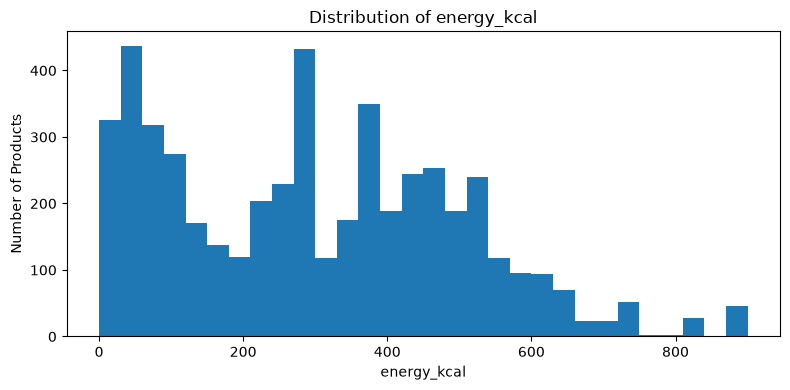

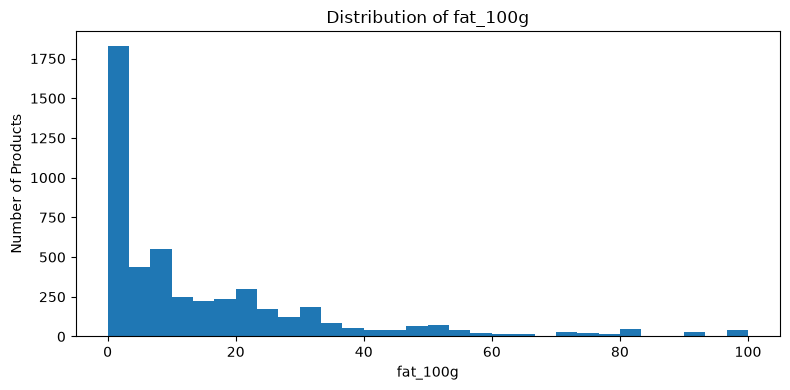

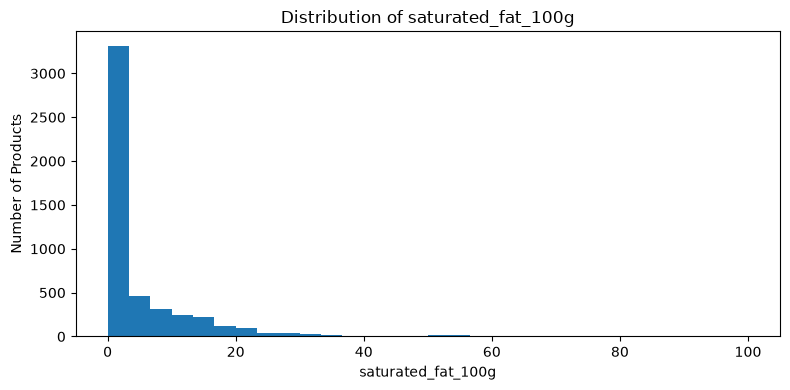

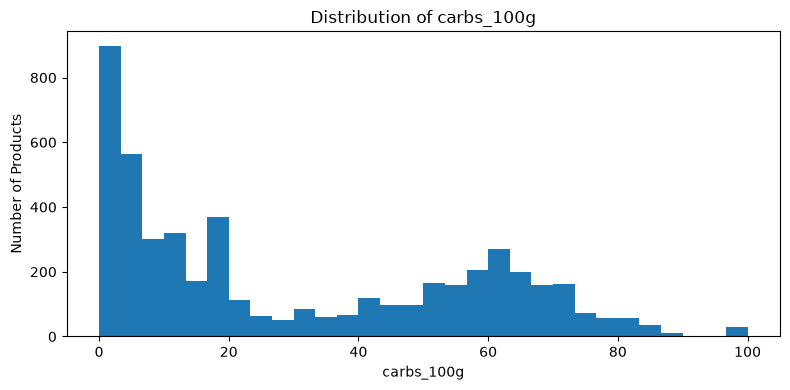

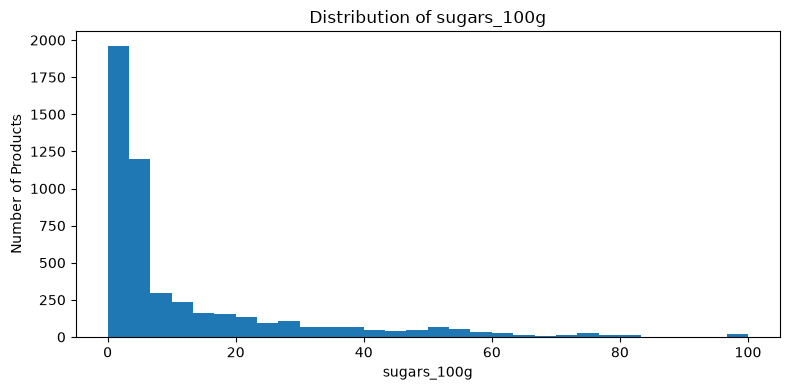

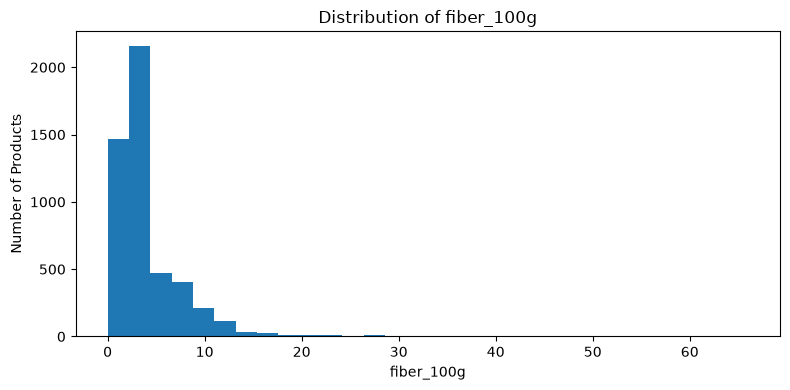

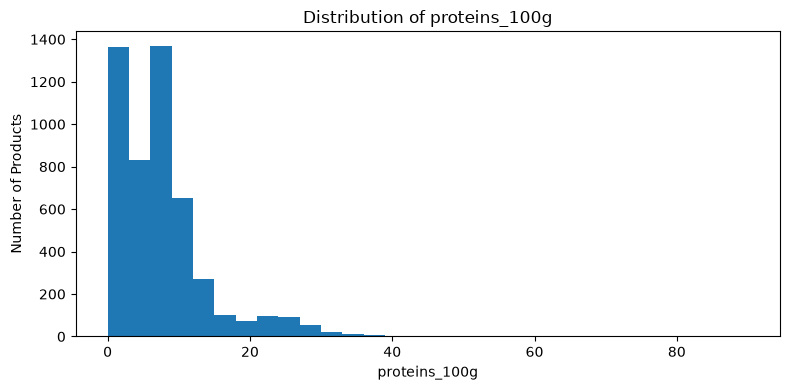

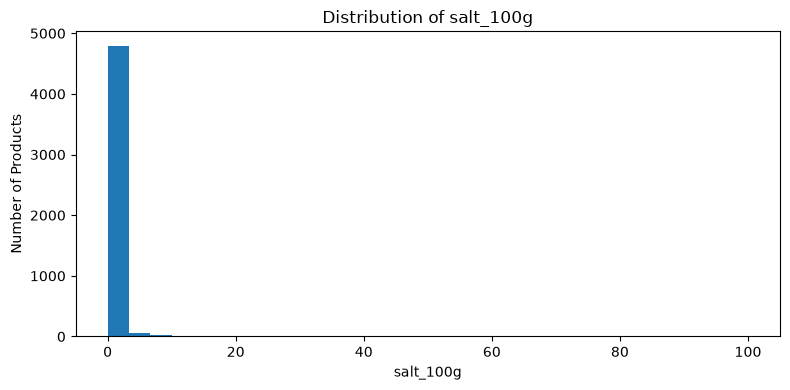

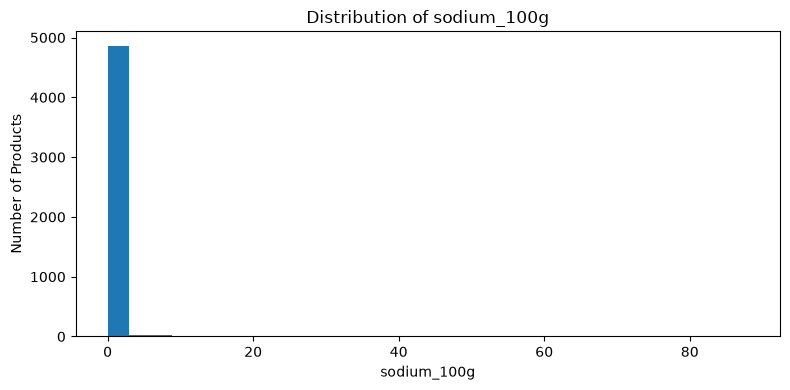

In [109]:
# ============================================
# STEP 5A: NUTRITION DATA VISUALIZATION
# ============================================

import matplotlib.pyplot as plt

nutrition_cols = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
]

for col in nutrition_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(model_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Products")
    plt.tight_layout()
    plt.show()

In [110]:
# ============================================
# STEP 5B: NUTRITIONAL RISK FEATURES
# ============================================

flag_cols = [
    "high_sugar",
    "high_fat",
    "high_saturated_fat",
    "high_salt",
    "high_calorie",
    "has_allergens"
]

flag_counts = model_df[flag_cols].sum().sort_values(ascending=False)

print("NUTRITIONAL RISK INDICATORS")
print("============================")
print(flag_counts)

plt.figure(figsize=(9, 5))
flag_counts.plot(kind="bar")
plt.title("Products with Nutritional Risk Indicators")
plt.xlabel("Feature")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

KeyError: "None of [Index(['high_sugar', 'high_fat', 'high_saturated_fat', 'high_salt',\n       'high_calorie', 'has_allergens'],\n      dtype='str')] are in the [columns]"

In [111]:
# ============================================
# STEP 4: RECREATE ENGINEERED FEATURES
# ============================================

# Nutritional risk indicators

model_df["high_sugar"] = (
    model_df["sugars_100g"] >= 20
).astype(int)

model_df["high_fat"] = (
    model_df["fat_100g"] >= 20
).astype(int)

model_df["high_saturated_fat"] = (
    model_df["saturated_fat_100g"] >= 5
).astype(int)

model_df["high_salt"] = (
    model_df["salt_100g"] >= 1.5
).astype(int)

model_df["high_calorie"] = (
    model_df["energy_kcal"] >= 400
).astype(int)

# Allergen indicator
model_df["has_allergens"] = (
    model_df["allergens"]
    .fillna("Unknown")
    .astype(str)
    .str.lower()
    .ne("unknown")
    .astype(int)
)

# Count ingredients
model_df["ingredient_count"] = (
    model_df["ingredients"]
    .fillna("")
    .astype(str)
    .apply(
        lambda x: len([
            i for i in x.split(",")
            if i.strip()
        ])
        if x.strip()
        else 0
    )
)

print("FEATURE ENGINEERING COMPLETE")
print("=============================")

feature_cols = [
    "high_sugar",
    "high_fat",
    "high_saturated_fat",
    "high_salt",
    "high_calorie",
    "has_allergens",
    "ingredient_count"
]

display(model_df[feature_cols].head(10))

FEATURE ENGINEERING COMPLETE


,high_sugar,high_fat,high_saturated_fat,high_salt,high_calorie,has_allergens,ingredient_count
0,0,0,0,0,0,0,1
1,0,0,0,0,0,1,5
2,0,0,0,0,0,0,7
3,0,0,0,0,0,0,1
4,0,0,0,0,0,0,1
5,0,0,0,0,0,1,1
6,0,0,0,0,0,1,1
7,0,0,0,0,0,1,3
8,0,0,0,0,0,1,1
9,0,1,1,0,0,1,7


NUTRITIONAL RISK INDICATORS
has_allergens         3330
high_calorie          1597
high_saturated_fat    1441
high_fat              1430
high_sugar             958
high_salt              588
dtype: int64


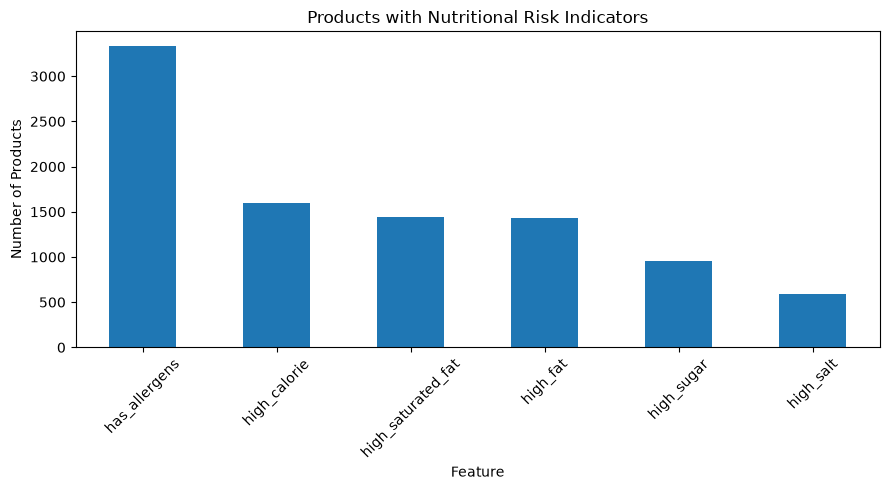

In [112]:
# ============================================
# STEP 5B: NUTRITIONAL RISK VISUALIZATION
# ============================================

flag_cols = [
    "high_sugar",
    "high_fat",
    "high_saturated_fat",
    "high_salt",
    "high_calorie",
    "has_allergens"
]

flag_counts = model_df[flag_cols].sum().sort_values(ascending=False)

print("NUTRITIONAL RISK INDICATORS")
print("============================")
print(flag_counts)

plt.figure(figsize=(9, 5))
flag_counts.plot(kind="bar")
plt.title("Products with Nutritional Risk Indicators")
plt.xlabel("Feature")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [113]:
# ============================================
# STEP 6: CREATE CLASSIFICATION TARGET
# ============================================

def classify_risk(row):

    risk_score = (
        row["high_sugar"]
        + row["high_fat"]
        + row["high_saturated_fat"]
        + row["high_salt"]
        + row["high_calorie"]
        + row["has_allergens"]
    )

    if risk_score >= 4:
        return "High Risk"
    elif risk_score >= 2:
        return "Moderate Risk"
    else:
        return "Low Risk"


model_df["risk_level"] = model_df.apply(
    classify_risk,
    axis=1
)

print("CLASSIFICATION TARGET CREATED")
print("==============================")

print(model_df["risk_level"].value_counts())

display(
    model_df[
        [
            "product_name",
            "high_sugar",
            "high_fat",
            "high_saturated_fat",
            "high_salt",
            "high_calorie",
            "has_allergens",
            "risk_level"
        ]
    ].head(10)
)

CLASSIFICATION TARGET CREATED
risk_level
Low Risk         2649
Moderate Risk    1301
High Risk        1009
Name: count, dtype: int64


,product_name,high_sugar,high_fat,high_saturated_fat,high_salt,high_calorie,has_allergens,risk_level
0,Sidi Ali,0,0,0,0,0,0,Low Risk
1,Perly,0,0,0,0,0,1,Low Risk
2,Sidi Ali,0,0,0,0,0,0,Low Risk
3,Eau minérale naturelle,0,0,0,0,0,0,Low Risk
4,اكوافينا,0,0,0,0,0,0,Low Risk
5,Lait,0,0,0,0,0,1,Low Risk
6,Eau De Source,0,0,0,0,0,1,Low Risk
7,Fromage Blanc Nature,0,0,0,0,0,1,Low Risk
8,uht jaouda 1L,0,0,0,0,0,1,Low Risk
9,Jben,0,1,1,0,0,1,Moderate Risk


In [114]:
print(df.shape)
print(df.columns.tolist())

(4997, 24)
['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type']


In [115]:
print(model_df.shape)
print(model_df.columns.tolist())

(4959, 32)
['product_name', 'brands', 'categories', 'ingredients', 'nutriscore_grade', 'nova_group', 'ecoscore_grade', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'food_type', 'high_sugar', 'high_fat', 'high_saturated_fat', 'high_salt', 'high_calorie', 'has_allergens', 'ingredient_count', 'risk_level']


In [2]:
import pandas as pd
from pathlib import Path

# Notebook is inside: data/notebooks/
# Dataset is inside: data/
DATA_PATH = Path("../final_clean_dataset.csv")

df = pd.read_csv(DATA_PATH, low_memory=False)

print("=" * 60)
print("FINAL CLEAN DATASET CHECK")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isna().sum().sum())

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(i, col)

FileNotFoundError: [Errno 2] No such file or directory: '..\\final_clean_dataset.csv'

In [5]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("data") / "final_clean_dataset.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print("=" * 60)
print("FINAL CLEAN DATASET CHECK")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isna().sum().sum())

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(i, col)

FileNotFoundError: [Errno 2] No such file or directory: 'data\\final_clean_dataset.csv'

In [6]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles in current directory:")
for file in Path(".").iterdir():
    print(file)

Current working directory:
c:\Projects\Ingredient_Check_AI\notebooks

Files in current directory:
data_preparation.ipynb


In [7]:
import pandas as pd
from pathlib import Path

# Current notebook location:
# C:\Projects\Ingredient_Check_AI\notebooks

# Go one folder up to Ingredient_Check_AI,
# then enter the data folder.
DATA_PATH = Path("../data/final_clean_dataset.csv")

df = pd.read_csv(DATA_PATH, low_memory=False)

print("=" * 60)
print("FINAL CLEAN DATASET CHECK")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isna().sum().sum())

print("\nColumn names:")
for i, col in enumerate(df.columns, 1):
    print(i, col)

FINAL CLEAN DATASET CHECK
Rows: 4959
Columns: 66
Missing values: 0

Column names:
1 product_name
2 brands
3 categories
4 ingredients
5 nutriscore_grade
6 nova_group
7 ecoscore_grade
8 allergens
9 energy_kcal
10 fat_100g
11 saturated_fat_100g
12 carbs_100g
13 sugars_100g
14 fiber_100g
15 proteins_100g
16 salt_100g
17 sodium_100g
18 contains_gluten
19 contains_dairy
20 contains_nuts
21 contains_soy
22 contains_eggs
23 contains_fish
24 food_type
25 product_key
26 original_product
27 original_brand
28 edamam_food_id
29 edamam_product_name
30 edamam_brand
31 edamam_category
32 api_calories
33 api_protein
34 api_fat
35 api_carbs
36 api_fiber
37 api_ingredients
38 match_score
39 product_name_openfood
40 api_product_name
41 api_brands
42 api_ingredients_openfood
43 api_allergens
44 api_code
45 cor_product_id
46 cor_product_name
47 cor_brand
48 cor_match_score
49 original_product_usda
50 original_brand_usda
51 usda_fdc_id
52 usda_product_name
53 usda_brand
54 usda_data_type
55 usda_match_score
